In [1]:
import pandas as pd
import duckdb as dd
import xlwings as xw

In [2]:
xw.books.active.fullname

'C:\\Users\\Dell\\Downloads\\生产每日交货清单.xlsx'

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime, timedelta
import warnings
import os
warnings.filterwarnings('ignore')

# 設置中文字體
plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

# 創建輸出資料夾
output_folder = '部门产能报告'
if not os.path.exists(output_folder):
    os.makedirs(output_folder)
    print(f"📁 創建資料夾: {output_folder}")

# ============================================
# 1. 讀取 Excel 資料
# ============================================
print("=" * 70)
print("📊 各發出部門 - 生產交貨資料分析與產能預測")
print("=" * 70)

# 讀取 Excel 檔案
file_path = r'C:\Users\Dell\Downloads\生产每日交货清单.xlsx'
print(f"\n📂 讀取檔案: {file_path}")

try:
    df_raw = pd.read_excel(file_path, sheet_name='生产每日交货清单')
    print(f"✅ 成功讀取 {len(df_raw)} 筆資料")
except FileNotFoundError:
    print(f"❌ 檔案不存在: {file_path}")
    print("請確認檔案路徑是否正確")
    exit()
except Exception as e:
    print(f"❌ 讀取失敗: {e}")
    exit()

# 檢查必要欄位
required_columns = ['开单日期', '发出部门', '交货数']
missing_cols = [col for col in required_columns if col not in df_raw.columns]
if missing_cols:
    print(f"❌ 缺少必要欄位: {missing_cols}")
    print(f"檔案中現有欄位: {df_raw.columns.tolist()}")
    exit()

# 資料清理
df_raw['开单日期'] = pd.to_datetime(df_raw['开单日期'])
df_raw = df_raw.dropna(subset=['开单日期', '发出部门', '交货数'])
df_raw = df_raw[df_raw['交货数'] > 0]
df_raw = df_raw.sort_values('开单日期')

# 獲取所有部門
departments = df_raw['发出部门'].unique()
print(f"\n📋 發現 {len(departments)} 個發出部門:")
for i, dept in enumerate(departments, 1):
    dept_data = df_raw[df_raw['发出部门'] == dept]
    print(f"   {i}. {dept} ({len(dept_data)} 筆資料, 總交貨: {dept_data['交货数'].sum():,} 件)")

# ============================================
# 2. 定義預測函數（以車縫2組範本為基礎）
# ============================================
def forecast_dept(df_dept, dept_name, forecast_days=30):
    """對單一部門進行產能預測（以車縫2組範本為基礎）"""
    
    if len(df_dept) < 3:
        return None
    
    # 按日期彙總每日交貨量
    daily_dept = df_dept.groupby('开单日期')['交货数'].sum().reset_index()
    daily_dept = daily_dept.set_index('开单日期')
    
    # 補齊缺失日期
    date_range = pd.date_range(start=daily_dept.index.min(), end=daily_dept.index.max(), freq='D')
    daily_dept = daily_dept.reindex(date_range, fill_value=0)
    daily_dept.columns = ['交货数']
    
    # 計算歷史統計
    historical_daily_avg = daily_dept['交货数'].mean()
    historical_total = daily_dept['交货数'].sum()
    historical_days = len(daily_dept)
    
    # 計算不同時間窗口的移動平均
    windows = [3, 7, 14, 30]
    valid_windows = [w for w in windows if w <= len(daily_dept)]
    
    if valid_windows:
        window = max(valid_windows)
        ma = daily_dept['交货数'].rolling(window=window).mean().dropna()
        if len(ma) > 0:
            recent_ma = ma.iloc[-1]
        else:
            recent_ma = historical_daily_avg
    else:
        recent_ma = historical_daily_avg
    
    # 計算成長趨勢
    if len(daily_dept) >= 28:
        recent_14 = daily_dept['交货数'].tail(14).mean()
        older_14 = daily_dept['交货数'].head(14).mean()
        growth_rate = ((recent_14 - older_14) / older_14 * 100) if older_14 > 0 else 0
    elif len(daily_dept) >= 14:
        recent_7 = daily_dept['交货数'].tail(7).mean()
        older_7 = daily_dept['交货数'].head(7).mean()
        growth_rate = ((recent_7 - older_7) / older_7 * 100) if older_7 > 0 else 0
    else:
        growth_rate = 0
    
    # 計算週期性（星期幾效應）
    has_seasonality = False
    weekday_avg = None
    if len(daily_dept) >= 14:
        daily_dept_copy = daily_dept.copy()
        daily_dept_copy['星期'] = daily_dept_copy.index.dayofweek
        weekday_avg = daily_dept_copy.groupby('星期')['交货数'].mean()
        has_seasonality = weekday_avg.std() > weekday_avg.mean() * 0.3 if weekday_avg.mean() > 0 else False
    
    # 預測未來
    forecast = []
    forecast_base = recent_ma
    
    if has_seasonality and len(daily_dept) >= 14 and weekday_avg is not None:
        # 考慮星期幾的週期性
        for i in range(forecast_days):
            future_date = daily_dept.index.max() + timedelta(days=i+1)
            weekday = future_date.weekday()
            base_value = weekday_avg[weekday] if weekday in weekday_avg.index else historical_daily_avg
            trend_factor = 1 + (growth_rate / 100) * (i / forecast_days)
            forecast.append(max(0, base_value * trend_factor))
        model_name = "週期性加權移動平均"
    elif abs(growth_rate) > 1:
        # 有明顯趨勢，使用加權移動平均
        weights = np.array([0.5, 0.3, 0.2])
        recent_values = daily_dept['交货数'].tail(min(3, len(daily_dept))).values
        if len(recent_values) == len(weights):
            weighted_avg = np.sum(recent_values * weights)
        else:
            weighted_avg = recent_ma
        
        for i in range(forecast_days):
            trend_factor = 1 + (growth_rate / 100) * (i / forecast_days)
            forecast.append(max(0, weighted_avg * trend_factor))
        model_name = "趨勢調整加權移動平均"
    else:
        # 平穩狀態，使用移動平均
        for i in range(forecast_days):
            forecast.append(max(0, recent_ma))
        model_name = "簡單移動平均"
    
    # 添加自然波動
    if forecast_base > 0 and len(daily_dept) > 7:
        np.random.seed(42)
        noise_level = min(0.15, daily_dept['交货数'].std() / (forecast_base + 1) * 0.5)
        noise = np.random.normal(0, forecast_base * noise_level, forecast_days)
        forecast = [max(0, f + n) for f, n in zip(forecast, noise)]
    
    return {
        '部门': dept_name,
        '模型': model_name,
        '历史总产能': round(historical_total, 0),
        '历史日均产能': round(historical_daily_avg, 0),
        '预测日均产能': round(np.mean(forecast), 0),
        '预测总产能': round(np.sum(forecast), 0),
        '增长趋势': round(growth_rate, 1),
        '预测值': forecast,
        '历史数据天数': historical_days,
        'has_seasonality': has_seasonality
    }


# ============================================
# 3. 對每個部門進行預測並生成獨立報告
# ============================================
print("\n" + "=" * 70)
print("🔮 開始為每個部門生成獨立報告...")
print("=" * 70)

all_results = []

for dept in departments:
    print(f"\n{'='*50}")
    print(f"📌 正在處理: {dept}")
    print(f"{'='*50}")
    
    df_dept = df_raw[df_raw['发出部门'] == dept].copy()
    
    # 添加時間維度
    df_dept['日期'] = df_dept['开单日期'].dt.date
    df_dept['年週'] = df_dept['开单日期'].dt.strftime('%Y-W%W')
    df_dept['年月'] = df_dept['开单日期'].dt.strftime('%Y-%m')
    df_dept['季度'] = df_dept['开单日期'].dt.to_period('Q').astype(str)
    df_dept['年度'] = df_dept['开单日期'].dt.year
    
    # 計算各時間維度統計
    daily_stats = df_dept.groupby(['日期'])['交货数'].sum().reset_index()
    daily_stats = daily_stats.sort_values('日期', ascending=False)
    
    weekly_stats = df_dept.groupby(['年週'])['交货数'].sum().reset_index()
    weekly_stats = weekly_stats.sort_values('年週')
    
    monthly_stats = df_dept.groupby(['年月'])['交货数'].sum().reset_index()
    monthly_stats = monthly_stats.sort_values('年月')
    
    quarterly_stats = df_dept.groupby(['季度'])['交货数'].sum().reset_index()
    quarterly_stats = quarterly_stats.sort_values('季度')
    
    yearly_stats = df_dept.groupby(['年度'])['交货数'].sum().reset_index()
    yearly_stats = yearly_stats.sort_values('年度')
    
    # 款號統計
    if '款号' in df_dept.columns:
        style_stats = df_dept.groupby(['款号'])['交货数'].agg(['sum', 'mean', 'count']).round(2)
        style_stats.columns = ['總交貨數', '平均交貨數', '交易次數']
        style_stats = style_stats.sort_values('總交貨數', ascending=False)
    else:
        style_stats = None
    
    # 基本統計
    active_days = df_dept['开单日期'].dt.date.nunique()
    
    # 執行預測
    result = forecast_dept(df_dept, dept, forecast_days=30)
    
    if result is None:
        print(f"   ⚠️ {dept}: 資料不足 (僅{len(df_dept)}筆)，無法進行可靠預測")
        continue
    
    all_results.append(result)
    
    # 準備預測結果表格
    daily_total = df_dept.groupby('开单日期')['交货数'].sum()
    forecast_dates = pd.date_range(start=daily_total.index.max() + timedelta(days=1), periods=30, freq='D')
    forecast_table = pd.DataFrame({
        '預測日期': forecast_dates,
        '預測交貨數': [round(v) for v in result['预测值']]
    })
    
    # 交貨次數分布
    bins = [0, 500, 1000, 2000, 5000, 10000, 50000, 100000]
    labels = ['<500', '500-1000', '1000-2000', '2000-5000', '5000-10000', '10000-50000', '>50000']
    df_dept['交貨區間'] = pd.cut(df_dept['交货数'], bins=bins, labels=labels)
    dist_stats = df_dept['交貨區間'].value_counts().sort_index().reset_index()
    dist_stats.columns = ['交貨區間(件)', '次數']
    
    # 生成檔名（去除特殊字符）
    safe_name = dept.replace('/', '_').replace('\\', '_').replace(' ', '_').replace('組', '组')
    excel_file = os.path.join(output_folder, f'{safe_name}_生产报告.xlsx')
    
    # ============================================
    # 4. 匯出該部門的 Excel 報告
    # ============================================
    try:
        with pd.ExcelWriter(excel_file, engine='openpyxl') as writer:
            # 部門概況
            summary_df = pd.DataFrame([{
                '部門名稱': result['部门'],
                '預測模型': result['模型'],
                '資料筆數': len(df_dept),
                '活躍天數': active_days,
                '歷史總產能(件)': result['历史总产能'],
                '歷史日均產能(件/天)': result['历史日均产能'],
                '預測30天總產能(件)': result['预测总产能'],
                '預測30天日均產能(件/天)': result['预测日均产能'],
                '成長趨勢(%)': result['增长趋势'],
                '週期性模式': '是' if result['has_seasonality'] else '否'
            }])
            summary_df.to_excel(writer, sheet_name='部門概況', index=False)
            
            # 原始資料
            df_dept.to_excel(writer, sheet_name='原始資料', index=False)
            
            # 日報
            daily_stats.to_excel(writer, sheet_name='日報', index=False)
            
            # 週報
            weekly_stats.to_excel(writer, sheet_name='週報', index=False)
            
            # 月報
            monthly_stats.to_excel(writer, sheet_name='月報', index=False)
            
            # 季報
            quarterly_stats.to_excel(writer, sheet_name='季報', index=False)
            
            # 年報
            yearly_stats.to_excel(writer, sheet_name='年報', index=False)
            
            # 款號統計
            if style_stats is not None:
                style_stats.to_excel(writer, sheet_name='款號統計')
            
            # 每日預測明細
            forecast_table.to_excel(writer, sheet_name='每日預測明細', index=False)
            
            # 基本統計
            basic_stats = pd.DataFrame({
                '統計項目': ['總交貨件數', '總交易次數', '平均每次交貨', '最大單次交貨', '最小單次交貨', '標準差', '活躍天數', '日均交貨'],
                '數值': [
                    f"{df_dept['交货数'].sum():,}",
                    len(df_dept),
                    f"{df_dept['交货数'].mean():.0f}",
                    f"{df_dept['交货数'].max():,}",
                    f"{df_dept['交货数'].min():,}",
                    f"{df_dept['交货数'].std():.0f}",
                    active_days,
                    f"{df_dept['交货数'].sum() / active_days:.0f}"
                ]
            })
            basic_stats.to_excel(writer, sheet_name='基本統計', index=False)
            
            # 交貨次數分布
            dist_stats.to_excel(writer, sheet_name='交貨次數分布', index=False)
        
        print(f"   ✅ Excel 報告已儲存: {excel_file}")
        
    except Exception as e:
        print(f"   ⚠️ Excel 匯出失敗: {e}")
    
    # ============================================
    # 5. 繪製該部門的詳細預測圖（以車縫2組範本為基礎）
    # ============================================
    try:
        fig, axes = plt.subplots(2, 2, figsize=(15, 10))
        
        # 圖1: 每日交貨趨勢
        daily_total = df_dept.groupby('开单日期')['交货数'].sum()
        daily_ma7 = daily_total.rolling(window=7).mean()
        daily_ma30 = daily_total.rolling(window=30).mean()
        
        axes[0,0].plot(daily_total.index, daily_total.values, 'b-', linewidth=1, alpha=0.5, label='每日交貨')
        axes[0,0].plot(daily_ma7.index, daily_ma7.values, 'r-', linewidth=2, label='7日移動平均')
        if len(daily_total) >= 30:
            axes[0,0].plot(daily_ma30.index, daily_ma30.values, 'g-', linewidth=2, label='30日移動平均')
        axes[0,0].set_title(f'{dept} - 每日交貨趨勢', fontsize=12, fontweight='bold')
        axes[0,0].set_xlabel('日期')
        axes[0,0].set_ylabel('交貨數 (件)')
        axes[0,0].legend()
        axes[0,0].tick_params(axis='x', rotation=45)
        axes[0,0].grid(True, alpha=0.3)
        
        # 圖2: 每月交貨趨勢
        monthly_total = df_dept.groupby(df_dept['开单日期'].dt.to_period('M'))['交货数'].sum()
        axes[0,1].bar(range(len(monthly_total)), monthly_total.values, color='skyblue', edgecolor='navy')
        axes[0,1].set_title(f'{dept} - 每月交貨趨勢', fontsize=12, fontweight='bold')
        axes[0,1].set_xlabel('月份')
        axes[0,1].set_ylabel('交貨數 (件)')
        axes[0,1].set_xticks(range(len(monthly_total)))
        axes[0,1].set_xticklabels([str(m) for m in monthly_total.index], rotation=45)
        axes[0,1].grid(True, alpha=0.3)
        
        # 圖3: 交貨次數分布
        bins = [0, 500, 1000, 2000, 5000, 10000, 50000, 100000]
        labels = ['<500', '500-1000', '1000-2000', '2000-5000', '5000-10000', '10000-50000', '>50000']
        df_dept['交貨區間'] = pd.cut(df_dept['交货数'], bins=bins, labels=labels)
        count_dist = df_dept['交貨區間'].value_counts().sort_index()
        axes[1,0].bar(range(len(count_dist)), count_dist.values, color='lightcoral', edgecolor='darkred')
        axes[1,0].set_title(f'{dept} - 交貨次數分布', fontsize=12, fontweight='bold')
        axes[1,0].set_xlabel('交貨數量區間 (件)')
        axes[1,0].set_ylabel('次數')
        axes[1,0].set_xticks(range(len(count_dist)))
        axes[1,0].set_xticklabels(count_dist.index, rotation=45)
        for i, (idx, val) in enumerate(count_dist.items()):
            axes[1,0].text(i, val + 0.5, str(val), ha='center', va='bottom')
        axes[1,0].grid(True, alpha=0.3, axis='y')
        
        # 圖4: 產能預測
        last_30_days = daily_total.tail(30)
        forecast_values = result['预测值']
        
        if len(last_30_days) > 0:
            axes[1,1].plot(last_30_days.index, last_30_days.values, 'b-o', linewidth=2, markersize=4, label='歷史數據 (過去30天)')
        
        future_dates = pd.date_range(start=daily_total.index.max() + timedelta(days=1), periods=30, freq='D')
        axes[1,1].plot(future_dates, forecast_values, 'r--o', linewidth=2, markersize=4, label='未來30天預測')
        
        hist_avg = result['历史日均产能']
        pred_avg = result['预测日均产能']
        axes[1,1].axhline(y=hist_avg, color='blue', linestyle=':', alpha=0.5, label=f'歷史日均: {hist_avg:.0f}件')
        axes[1,1].axhline(y=pred_avg, color='red', linestyle=':', alpha=0.5, label=f'預測日均: {pred_avg:.0f}件')
        
        axes[1,1].set_title(f'{dept} - 產能預測 (未來30天)', fontsize=12, fontweight='bold')
        axes[1,1].set_xlabel('日期')
        axes[1,1].set_ylabel('交貨數 (件)')
        axes[1,1].legend()
        axes[1,1].tick_params(axis='x', rotation=45)
        axes[1,1].grid(True, alpha=0.3)
        
        plt.tight_layout()
        image_file = os.path.join(output_folder, f'{safe_name}_产能预测.png')
        plt.savefig(image_file, dpi=150, bbox_inches='tight', facecolor='white')
        plt.close()
        
        print(f"   ✅ 預測圖已儲存: {image_file}")
        
    except Exception as e:
        print(f"   ⚠️ 圖表繪製失敗: {e}")
        plt.close()
    
    # 顯示預測結果摘要
    print(f"\n   📊 {dept} 預測結果摘要:")
    print(f"      - 資料筆數: {len(df_dept)} 筆")
    print(f"      - 活躍天數: {active_days} 天")
    print(f"      - 歷史總產能: {result['历史总产能']:,.0f} 件")
    print(f"      - 歷史日均: {result['历史日均产能']:,.0f} 件/天")
    print(f"      - 預測日均: {result['预测日均产能']:,.0f} 件/天")
    print(f"      - 預測30天總產能: {result['预测总产能']:,.0f} 件")
    print(f"      - 成長趨勢: {result['增长趋势']:+.1f}%")
    print(f"      - 使用模型: {result['模型']}")
    if result['has_seasonality']:
        print(f"      - 週期性: 偵測到星期效應")

# ============================================
# 6. 生成匯總報告
# ============================================
print("\n" + "=" * 70)
print("📊 生成匯總報告")
print("=" * 70)

if all_results:
    # 匯總所有部門預測結果
    summary_all = pd.DataFrame([{
        '部門': r['部门'],
        '預測模型': r['模型'],
        '資料筆數': len(df_raw[df_raw['发出部门'] == r['部门']]),
        '歷史總產能(件)': r['历史总产能'],
        '歷史日均產能(件/天)': r['历史日均产能'],
        '預測30天總產能(件)': r['预测总产能'],
        '預測30天日均產能(件/天)': r['预测日均产能'],
        '成長趨勢(%)': r['增长趋势'],
        '週期性模式': '是' if r['has_seasonality'] else '否'
    } for r in all_results])
    
    summary_all = summary_all.sort_values('預測30天總產能(件)', ascending=False)
    
    # 儲存匯總報告
    summary_file = os.path.join(output_folder, '00_各部门汇总报告.xlsx')
    try:
        with pd.ExcelWriter(summary_file, engine='openpyxl') as writer:
            summary_all.to_excel(writer, sheet_name='各部門預測匯總', index=False)
            
            # 各部門歷史總統計
            dept_summary = df_raw.groupby('发出部门').agg({
                '交货数': ['sum', 'mean', 'count'],
                '开单日期': lambda x: f"{x.min().strftime('%Y-%m-%d')} ~ {x.max().strftime('%Y-%m-%d')}"
            }).round(2)
            dept_summary.columns = ['總交貨數', '平均交貨數', '交易次數', '日期範圍']
            dept_summary.to_excel(writer, sheet_name='各部門歷史統計')
            
            # 整體時間維度統計
            df_raw['年月'] = df_raw['开单日期'].dt.strftime('%Y-%m')
            monthly_all = df_raw.groupby(['年月', '发出部门'])['交货数'].sum().reset_index()
            monthly_pivot = monthly_all.pivot(index='年月', columns='发出部门', values='交货数').fillna(0)
            monthly_pivot.to_excel(writer, sheet_name='各部門月報')
        
        print(f"✅ 匯總報告已儲存: {summary_file}")
    except Exception as e:
        print(f"⚠️ 匯總報告儲存失敗: {e}")

# ============================================
# 7. 最終摘要報告
# ============================================
print("\n" + "=" * 70)
print("📋 各部門產能預測摘要報告")
print("=" * 70)

print(f"\n📊 整體統計:")
print(f"   - 部門總數: {len(departments)}")
print(f"   - 成功預測部門數: {len(all_results)}")
print(f"   - 資料總筆數: {len(df_raw):,}")
print(f"   - 歷史總交貨量: {df_raw['交货数'].sum():,} 件")

if all_results:
    total_forecast = sum([r['预测总产能'] for r in all_results])
    print(f"\n🔮 各部門預測30天總產能合計: {total_forecast:,.0f} 件")
    print(f"📈 預測30天整體日均產能: {total_forecast/30:.0f} 件/天")
    
    print("\n📌 各部門預測明細 (依預測產能排序):")
    sorted_results = sorted(all_results, key=lambda x: x['预测总产能'], reverse=True)
    for i, r in enumerate(sorted_results, 1):
        growth_symbol = "📈" if r['增长趋势'] > 3 else "📉" if r['增长趋势'] < -3 else "➡️"
        print(f"   {i}. {r['部门']}: {r['预测总产能']:>12,} 件 (日均: {r['预测日均产能']:>6,.0f} | 趨勢: {r['增长趋势']:>+6.1f}% {growth_symbol})")

print("\n" + "=" * 70)
print("📁 輸出檔案結構:")
print(f"\n{output_folder}/")
print("   ├── 00_各部门汇总报告.xlsx     (所有部門匯總)")
print("   ├── 車縫2组_生产报告.xlsx      (車縫2組完整報告)")
print("   ├── 車縫2组_产能预测.png       (車縫2組預測圖)")
print("   ├── 鈕壓_生产报告.xlsx          (鈕壓完整報告)")
print("   ├── 鈕壓_产能预测.png           (鈕壓預測圖)")
print("   └── ... (其他部門)")
print("=" * 70)

print("\n✨ 所有部門分析完成！")
print(f"📁 報告已儲存至: {os.path.abspath(output_folder)}")

📊 各發出部門 - 生產交貨資料分析與產能預測

📂 讀取檔案: C:\Users\Dell\Downloads\生产每日交货清单.xlsx
✅ 成功讀取 5811 筆資料

📋 發現 12 個發出部門:
   1. 車縫11組 (576 筆資料, 總交貨: 593,100 件)
   2. 車縫8組 (819 筆資料, 總交貨: 495,384 件)
   3. 車縫5組 (602 筆資料, 總交貨: 559,228 件)
   4. 車縫2組 (557 筆資料, 總交貨: 699,332 件)
   5. 車縫9組 (679 筆資料, 總交貨: 794,502 件)
   6. 車縫4組 (551 筆資料, 總交貨: 393,715 件)
   7. 車縫10組 (554 筆資料, 總交貨: 1,035,250 件)
   8. 車縫7組 (605 筆資料, 總交貨: 733,570 件)
   9. 包裝組 (1 筆資料, 總交貨: 2,100 件)
   10. 車縫3組 (653 筆資料, 總交貨: 1,082,709 件)
   11. 裝配組 (137 筆資料, 總交貨: 197,430 件)
   12. 鈕壓 (76 筆資料, 總交貨: 90,571 件)

🔮 開始為每個部門生成獨立報告...

📌 正在處理: 車縫11組
   ✅ Excel 報告已儲存: 部门产能报告\車縫11组_生产报告.xlsx
   ✅ 預測圖已儲存: 部门产能报告\車縫11组_产能预测.png

   📊 車縫11組 預測結果摘要:
      - 資料筆數: 576 筆
      - 活躍天數: 321 天
      - 歷史總產能: 593,100 件
      - 歷史日均: 1,041 件/天
      - 預測日均: 3,311 件/天
      - 預測30天總產能: 99,327 件
      - 成長趨勢: +439.4%
      - 使用模型: 週期性加權移動平均
      - 週期性: 偵測到星期效應

📌 正在處理: 車縫8組
   ✅ Excel 報告已儲存: 部门产能报告\車縫8组_生产报告.xlsx
   ✅ 預測圖已儲存: 部门产能报告\車縫8组_产能预测.png

   📊 車縫8組 預測結果摘要:
      - 資

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime, timedelta
import warnings
import os
warnings.filterwarnings('ignore')

# 設置中文字體
plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

# 創建輸出資料夾
output_folder = '部门产能报告'
if not os.path.exists(output_folder):
    os.makedirs(output_folder)
    print(f"📁 創建資料夾: {output_folder}")

# ============================================
# 1. 讀取 Excel 資料
# ============================================
print("=" * 70)
print("📊 各發出部門 - 生產交貨資料分析與產能預測")
print("=" * 70)

# 讀取 Excel 檔案
file_path = r'C:\Users\Dell\Downloads\生产每日交货清单.xlsx'
print(f"\n📂 讀取檔案: {file_path}")

try:
    df_raw = pd.read_excel(file_path, sheet_name='生产每日交货清单')
    print(f"✅ 成功讀取 {len(df_raw)} 筆資料")
except FileNotFoundError:
    print(f"❌ 檔案不存在: {file_path}")
    print("請確認檔案路徑是否正確")
    exit()
except Exception as e:
    print(f"❌ 讀取失敗: {e}")
    exit()

# 檢查必要欄位
required_columns = ['开单日期', '发出部门', '交货数']
missing_cols = [col for col in required_columns if col not in df_raw.columns]
if missing_cols:
    print(f"❌ 缺少必要欄位: {missing_cols}")
    print(f"檔案中現有欄位: {df_raw.columns.tolist()}")
    exit()

# 資料清理
df_raw['开单日期'] = pd.to_datetime(df_raw['开单日期'])
df_raw = df_raw.dropna(subset=['开单日期', '发出部门', '交货数'])
df_raw = df_raw[df_raw['交货数'] > 0]
df_raw = df_raw.sort_values('开单日期')

# 獲取所有部門
departments = df_raw['发出部门'].unique()
print(f"\n📋 發現 {len(departments)} 個發出部門:")
for i, dept in enumerate(departments, 1):
    dept_data = df_raw[df_raw['发出部门'] == dept]
    print(f"   {i}. {dept} ({len(dept_data)} 筆資料, 總交貨: {dept_data['交货数'].sum():,} 件)")

# ============================================
# 2. 定義預測函數
# ============================================
def forecast_dept(df_dept, dept_name, forecast_days=30):
    """對單一部門進行產能預測"""
    
    if len(df_dept) < 3:
        return None
    
    # 按日期彙總每日交貨量
    daily_dept = df_dept.groupby('开单日期')['交货数'].sum().reset_index()
    daily_dept = daily_dept.set_index('开单日期')
    
    # 補齊缺失日期
    date_range = pd.date_range(start=daily_dept.index.min(), end=daily_dept.index.max(), freq='D')
    daily_dept = daily_dept.reindex(date_range, fill_value=0)
    daily_dept.columns = ['交货数']
    
    # 計算歷史統計
    historical_daily_avg = daily_dept['交货数'].mean()
    historical_total = daily_dept['交货数'].sum()
    historical_days = len(daily_dept)
    
    # 計算不同時間窗口的移動平均
    windows = [3, 7, 14, 30]
    valid_windows = [w for w in windows if w <= len(daily_dept)]
    
    if valid_windows:
        window = max(valid_windows)
        ma = daily_dept['交货数'].rolling(window=window).mean().dropna()
        if len(ma) > 0:
            recent_ma = ma.iloc[-1]
        else:
            recent_ma = historical_daily_avg
    else:
        recent_ma = historical_daily_avg
    
    # 計算成長趨勢
    if len(daily_dept) >= 28:
        recent_14 = daily_dept['交货数'].tail(14).mean()
        older_14 = daily_dept['交货数'].head(14).mean()
        growth_rate = ((recent_14 - older_14) / older_14 * 100) if older_14 > 0 else 0
    elif len(daily_dept) >= 14:
        recent_7 = daily_dept['交货数'].tail(7).mean()
        older_7 = daily_dept['交货数'].head(7).mean()
        growth_rate = ((recent_7 - older_7) / older_7 * 100) if older_7 > 0 else 0
    else:
        growth_rate = 0
    
    # 計算週期性（星期幾效應）
    has_seasonality = False
    weekday_avg = None
    if len(daily_dept) >= 14:
        daily_dept_copy = daily_dept.copy()
        daily_dept_copy['星期'] = daily_dept_copy.index.dayofweek
        weekday_avg = daily_dept_copy.groupby('星期')['交货数'].mean()
        has_seasonality = weekday_avg.std() > weekday_avg.mean() * 0.3 if weekday_avg.mean() > 0 else False
    
    # 預測未來
    forecast = []
    forecast_base = recent_ma
    
    if has_seasonality and len(daily_dept) >= 14 and weekday_avg is not None:
        for i in range(forecast_days):
            future_date = daily_dept.index.max() + timedelta(days=i+1)
            weekday = future_date.weekday()
            base_value = weekday_avg[weekday] if weekday in weekday_avg.index else historical_daily_avg
            trend_factor = 1 + (growth_rate / 100) * (i / forecast_days)
            forecast.append(max(0, base_value * trend_factor))
        model_name = "週期性加權移動平均"
    elif abs(growth_rate) > 1:
        weights = np.array([0.5, 0.3, 0.2])
        recent_values = daily_dept['交货数'].tail(min(3, len(daily_dept))).values
        if len(recent_values) == len(weights):
            weighted_avg = np.sum(recent_values * weights)
        else:
            weighted_avg = recent_ma
        
        for i in range(forecast_days):
            trend_factor = 1 + (growth_rate / 100) * (i / forecast_days)
            forecast.append(max(0, weighted_avg * trend_factor))
        model_name = "趨勢調整加權移動平均"
    else:
        for i in range(forecast_days):
            forecast.append(max(0, recent_ma))
        model_name = "簡單移動平均"
    
    # 添加自然波動
    if forecast_base > 0 and len(daily_dept) > 7:
        np.random.seed(42)
        noise_level = min(0.15, daily_dept['交货数'].std() / (forecast_base + 1) * 0.5)
        noise = np.random.normal(0, forecast_base * noise_level, forecast_days)
        forecast = [max(0, f + n) for f, n in zip(forecast, noise)]
    
    return {
        '部门': dept_name,
        '模型': model_name,
        '历史总产能': round(historical_total, 0),
        '历史日均产能': round(historical_daily_avg, 0),
        '预测日均产能': round(np.mean(forecast), 0),
        '预测总产能': round(np.sum(forecast), 0),
        '增长趋势': round(growth_rate, 1),
        '预测值': forecast,
        '历史数据天数': historical_days,
        'has_seasonality': has_seasonality
    }


# ============================================
# 3. 對每個部門進行預測並生成獨立報告（加數量標籤）
# ============================================
print("\n" + "=" * 70)
print("🔮 開始為每個部門生成獨立報告...")
print("=" * 70)

all_results = []

for dept in departments:
    print(f"\n{'='*50}")
    print(f"📌 正在處理: {dept}")
    print(f"{'='*50}")
    
    df_dept = df_raw[df_raw['发出部门'] == dept].copy()
    
    # 添加時間維度
    df_dept['日期'] = df_dept['开单日期'].dt.date
    df_dept['年週'] = df_dept['开单日期'].dt.strftime('%Y-W%W')
    df_dept['年月'] = df_dept['开单日期'].dt.strftime('%Y-%m')
    df_dept['季度'] = df_dept['开单日期'].dt.to_period('Q').astype(str)
    df_dept['年度'] = df_dept['开单日期'].dt.year
    
    # 計算各時間維度統計
    daily_stats = df_dept.groupby(['日期'])['交货数'].sum().reset_index()
    daily_stats = daily_stats.sort_values('日期', ascending=False)
    
    weekly_stats = df_dept.groupby(['年週'])['交货数'].sum().reset_index()
    weekly_stats = weekly_stats.sort_values('年週')
    
    monthly_stats = df_dept.groupby(['年月'])['交货数'].sum().reset_index()
    monthly_stats = monthly_stats.sort_values('年月')
    
    quarterly_stats = df_dept.groupby(['季度'])['交货数'].sum().reset_index()
    quarterly_stats = quarterly_stats.sort_values('季度')
    
    yearly_stats = df_dept.groupby(['年度'])['交货数'].sum().reset_index()
    yearly_stats = yearly_stats.sort_values('年度')
    
    # 款號統計
    if '款号' in df_dept.columns:
        style_stats = df_dept.groupby(['款号'])['交货数'].agg(['sum', 'mean', 'count']).round(2)
        style_stats.columns = ['總交貨數', '平均交貨數', '交易次數']
        style_stats = style_stats.sort_values('總交貨數', ascending=False)
    else:
        style_stats = None
    
    # 基本統計
    active_days = df_dept['开单日期'].dt.date.nunique()
    
    # 執行預測
    result = forecast_dept(df_dept, dept, forecast_days=30)
    
    if result is None:
        print(f"   ⚠️ {dept}: 資料不足 (僅{len(df_dept)}筆)，無法進行可靠預測")
        continue
    
    all_results.append(result)
    
    # 準備預測結果表格
    daily_total = df_dept.groupby('开单日期')['交货数'].sum()
    forecast_dates = pd.date_range(start=daily_total.index.max() + timedelta(days=1), periods=30, freq='D')
    forecast_table = pd.DataFrame({
        '預測日期': forecast_dates,
        '預測交貨數': [round(v) for v in result['预测值']]
    })
    
    # 交貨次數分布
    bins = [0, 500, 1000, 2000, 5000, 10000, 50000, 100000]
    labels = ['<500', '500-1000', '1000-2000', '2000-5000', '5000-10000', '10000-50000', '>50000']
    df_dept['交貨區間'] = pd.cut(df_dept['交货数'], bins=bins, labels=labels)
    dist_stats = df_dept['交貨區間'].value_counts().sort_index().reset_index()
    dist_stats.columns = ['交貨區間(件)', '次數']
    
    # 生成檔名
    safe_name = dept.replace('/', '_').replace('\\', '_').replace(' ', '_').replace('組', '组')
    excel_file = os.path.join(output_folder, f'{safe_name}_生产报告.xlsx')
    
    # ============================================
    # 4. 匯出該部門的 Excel 報告
    # ============================================
    try:
        with pd.ExcelWriter(excel_file, engine='openpyxl') as writer:
            summary_df = pd.DataFrame([{
                '部門名稱': result['部门'],
                '預測模型': result['模型'],
                '資料筆數': len(df_dept),
                '活躍天數': active_days,
                '歷史總產能(件)': result['历史总产能'],
                '歷史日均產能(件/天)': result['历史日均产能'],
                '預測30天總產能(件)': result['预测总产能'],
                '預測30天日均產能(件/天)': result['预测日均产能'],
                '成長趨勢(%)': result['增长趋势'],
                '週期性模式': '是' if result['has_seasonality'] else '否'
            }])
            summary_df.to_excel(writer, sheet_name='部門概況', index=False)
            
            df_dept.to_excel(writer, sheet_name='原始資料', index=False)
            daily_stats.to_excel(writer, sheet_name='日報', index=False)
            weekly_stats.to_excel(writer, sheet_name='週報', index=False)
            monthly_stats.to_excel(writer, sheet_name='月報', index=False)
            quarterly_stats.to_excel(writer, sheet_name='季報', index=False)
            yearly_stats.to_excel(writer, sheet_name='年報', index=False)
            
            if style_stats is not None:
                style_stats.to_excel(writer, sheet_name='款號統計')
            
            forecast_table.to_excel(writer, sheet_name='每日預測明細', index=False)
            
            basic_stats = pd.DataFrame({
                '統計項目': ['總交貨件數', '總交易次數', '平均每次交貨', '最大單次交貨', '最小單次交貨', '標準差', '活躍天數', '日均交貨'],
                '數值': [
                    f"{df_dept['交货数'].sum():,}",
                    len(df_dept),
                    f"{df_dept['交货数'].mean():.0f}",
                    f"{df_dept['交货数'].max():,}",
                    f"{df_dept['交货数'].min():,}",
                    f"{df_dept['交货数'].std():.0f}",
                    active_days,
                    f"{df_dept['交货数'].sum() / active_days:.0f}"
                ]
            })
            basic_stats.to_excel(writer, sheet_name='基本統計', index=False)
            dist_stats.to_excel(writer, sheet_name='交貨次數分布', index=False)
        
        print(f"   ✅ Excel 報告已儲存: {excel_file}")
        
    except Exception as e:
        print(f"   ⚠️ Excel 匯出失敗: {e}")
    
    # ============================================
    # 5. 繪製圖表（加上數量標籤）
    # ============================================
    try:
        fig, axes = plt.subplots(2, 2, figsize=(16, 12))
        
        # ===== 圖1: 每日交貨趨勢 =====
        daily_total = df_dept.groupby('开单日期')['交货数'].sum()
        daily_ma7 = daily_total.rolling(window=7).mean()
        daily_ma30 = daily_total.rolling(window=30).mean()
        
        axes[0,0].plot(daily_total.index, daily_total.values, 'b-', linewidth=1, alpha=0.5, label='每日交貨')
        axes[0,0].plot(daily_ma7.index, daily_ma7.values, 'r-', linewidth=2, label='7日移動平均')
        if len(daily_total) >= 30:
            axes[0,0].plot(daily_ma30.index, daily_ma30.values, 'g-', linewidth=2, label='30日移動平均')
        axes[0,0].set_title(f'{dept} - 每日交貨趨勢', fontsize=12, fontweight='bold')
        axes[0,0].set_xlabel('日期')
        axes[0,0].set_ylabel('交貨數 (件)')
        axes[0,0].legend()
        axes[0,0].tick_params(axis='x', rotation=45)
        axes[0,0].grid(True, alpha=0.3)
        
        # ===== 圖2: 每月交貨趨勢（加上數量標籤）=====
        monthly_total = df_dept.groupby(df_dept['开单日期'].dt.to_period('M'))['交货数'].sum()
        months = range(len(monthly_total))
        month_labels = [str(m) for m in monthly_total.index]
        bar_colors = plt.cm.Blues(np.linspace(0.4, 0.9, len(monthly_total)))
        
        bars = axes[0,1].bar(months, monthly_total.values, color=bar_colors, edgecolor='navy', linewidth=1)
        axes[0,1].set_title(f'{dept} - 每月交貨趨勢', fontsize=12, fontweight='bold')
        axes[0,1].set_xlabel('月份')
        axes[0,1].set_ylabel('交貨數 (件)')
        axes[0,1].set_xticks(months)
        axes[0,1].set_xticklabels(month_labels, rotation=45)
        axes[0,1].grid(True, alpha=0.3, axis='y')
        
        # 在每個柱子上方添加數量標籤
        for bar, val in zip(bars, monthly_total.values):
            height = bar.get_height()
            if val >= 10000:
                label = f'{val/10000:.1f}萬'
            else:
                label = f'{int(val):,}'
            axes[0,1].text(bar.get_x() + bar.get_width()/2, height + max(monthly_total.values)*0.02,
                          label, ha='center', va='bottom', fontsize=9, fontweight='bold')
        
        # ===== 圖3: 交貨次數分布（加上數量標籤）=====
        bins = [0, 500, 1000, 2000, 5000, 10000, 50000, 100000]
        labels = ['<500', '500-1000', '1000-2000', '2000-5000', '5000-10000', '10000-50000', '>50000']
        df_dept['交貨區間'] = pd.cut(df_dept['交货数'], bins=bins, labels=labels)
        count_dist = df_dept['交貨區間'].value_counts().sort_index()
        
        bars = axes[1,0].bar(range(len(count_dist)), count_dist.values, color='lightcoral', edgecolor='darkred', linewidth=1)
        axes[1,0].set_title(f'{dept} - 交貨次數分布', fontsize=12, fontweight='bold')
        axes[1,0].set_xlabel('交貨數量區間 (件)')
        axes[1,0].set_ylabel('次數')
        axes[1,0].set_xticks(range(len(count_dist)))
        axes[1,0].set_xticklabels(count_dist.index, rotation=45)
        axes[1,0].grid(True, alpha=0.3, axis='y')
        
        # 添加數量標籤
        for bar, val in zip(bars, count_dist.values):
            axes[1,0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                          str(val), ha='center', va='bottom', fontsize=10, fontweight='bold')
        
        # ===== 圖4: 產能預測（加上數量標籤）=====
        last_30_days = daily_total.tail(30)
        forecast_values = result['预测值']
        
        if len(last_30_days) > 0:
            axes[1,1].plot(last_30_days.index, last_30_days.values, 'b-o', linewidth=2, markersize=4, label='歷史數據 (過去30天)')
        
        future_dates = pd.date_range(start=daily_total.index.max() + timedelta(days=1), periods=30, freq='D')
        line, = axes[1,1].plot(future_dates, forecast_values, 'r--o', linewidth=2, markersize=4, label='未來30天預測')
        
        # 在預測點上添加數量標籤（每隔5天標記一次）
        for i, (date, val) in enumerate(zip(future_dates, forecast_values)):
            if i % 5 == 0 or i == 29:  # 每5天標記一次，最後一天也標記
                if val >= 10000:
                    label = f'{val/10000:.1f}萬'
                else:
                    label = f'{int(val):,}'
                axes[1,1].annotate(label, xy=(date, val), xytext=(5, 5), 
                                  textcoords='offset points', fontsize=8, alpha=0.7)
        
        hist_avg = result['历史日均产能']
        pred_avg = result['预测日均产能']
        axes[1,1].axhline(y=hist_avg, color='blue', linestyle=':', alpha=0.5, label=f'歷史日均: {hist_avg:,.0f}件')
        axes[1,1].axhline(y=pred_avg, color='red', linestyle=':', alpha=0.5, label=f'預測日均: {pred_avg:,.0f}件')
        
        # 在預測平均值線末端添加標籤
        y_min, y_max = axes[1,1].get_ylim()
        axes[1,1].text(future_dates[-1], pred_avg, f'  {pred_avg:,.0f}', 
                      va='center', fontsize=9, color='red', fontweight='bold')
        
        axes[1,1].set_title(f'{dept} - 產能預測 (未來30天)\n預測30天總產能: {result["预测总产能"]:,.0f}件 | 成長趨勢: {result["增长趋势"]:+.1f}%', 
                           fontsize=12, fontweight='bold')
        axes[1,1].set_xlabel('日期')
        axes[1,1].set_ylabel('交貨數 (件)')
        axes[1,1].legend(loc='upper left')
        axes[1,1].tick_params(axis='x', rotation=45)
        axes[1,1].grid(True, alpha=0.3)
        
        plt.tight_layout()
        image_file = os.path.join(output_folder, f'{safe_name}_产能预测.png')
        plt.savefig(image_file, dpi=150, bbox_inches='tight', facecolor='white')
        plt.close()
        
        print(f"   ✅ 預測圖已儲存: {image_file}")
        
    except Exception as e:
        print(f"   ⚠️ 圖表繪製失敗: {e}")
        plt.close()
    
    # 顯示預測結果摘要
    print(f"\n   📊 {dept} 預測結果摘要:")
    print(f"      - 資料筆數: {len(df_dept)} 筆")
    print(f"      - 活躍天數: {active_days} 天")
    print(f"      - 歷史總產能: {result['历史总产能']:,.0f} 件")
    print(f"      - 歷史日均: {result['历史日均产能']:,.0f} 件/天")
    print(f"      - 預測30天總產能: {result['预测总产能']:,.0f} 件")
    print(f"      - 預測日均: {result['预测日均产能']:,.0f} 件/天")
    print(f"      - 成長趨勢: {result['增长趋势']:+.1f}%")

# ============================================
# 6. 生成匯總報告（加上數量標籤）
# ============================================
print("\n" + "=" * 70)
print("📊 生成匯總報告及匯總圖表")
print("=" * 70)

if all_results:
    # 匯總所有部門預測結果
    summary_all = pd.DataFrame([{
        '部門': r['部门'],
        '預測模型': r['模型'],
        '資料筆數': len(df_raw[df_raw['发出部门'] == r['部门']]),
        '歷史總產能(件)': r['历史总产能'],
        '歷史日均產能(件/天)': r['历史日均产能'],
        '預測30天總產能(件)': r['预测总产能'],
        '預測30天日均產能(件/天)': r['预测日均产能'],
        '成長趨勢(%)': r['增长趋势']
    } for r in all_results])
    
    summary_all = summary_all.sort_values('預測30天總產能(件)', ascending=False)
    
    # 儲存匯總報告
    summary_file = os.path.join(output_folder, '00_各部门汇总报告.xlsx')
    try:
        with pd.ExcelWriter(summary_file, engine='openpyxl') as writer:
            summary_all.to_excel(writer, sheet_name='各部門預測匯總', index=False)
            
            dept_summary = df_raw.groupby('发出部门').agg({
                '交货数': ['sum', 'mean', 'count'],
                '开单日期': lambda x: f"{x.min().strftime('%Y-%m-%d')} ~ {x.max().strftime('%Y-%m-%d')}"
            }).round(2)
            dept_summary.columns = ['總交貨數', '平均交貨數', '交易次數', '日期範圍']
            dept_summary.to_excel(writer, sheet_name='各部門歷史統計')
            
            df_raw['年月'] = df_raw['开单日期'].dt.strftime('%Y-%m')
            monthly_all = df_raw.groupby(['年月', '发出部门'])['交货数'].sum().reset_index()
            monthly_pivot = monthly_all.pivot(index='年月', columns='发出部门', values='交货数').fillna(0)
            monthly_pivot.to_excel(writer, sheet_name='各部門月報')
        
        print(f"✅ 匯總報告已儲存: {summary_file}")
    except Exception as e:
        print(f"⚠️ 匯總報告儲存失敗: {e}")
    
    # ============================================
    # 7. 繪製匯總圖表（加上數量標籤）
    # ============================================
    try:
        fig, axes = plt.subplots(2, 2, figsize=(16, 12))
        
        # 圖1: 各部門每月交貨趨勢（加上數量標籤）
        df_raw['年月'] = df_raw['开单日期'].dt.strftime('%Y-%m')
        monthly_pivot = df_raw.groupby(['年月', '发出部门'])['交货数'].sum().unstack(fill_value=0)
        
        for dept in monthly_pivot.columns:
            line, = axes[0,0].plot(monthly_pivot.index, monthly_pivot[dept], marker='o', linewidth=2, markersize=4, label=dept)
            # 在最後一個點添加標籤
            last_val = monthly_pivot[dept].iloc[-1]
            if last_val > 0:
                if last_val >= 10000:
                    label = f'{dept}: {last_val/10000:.1f}萬'
                else:
                    label = f'{dept}: {int(last_val):,}'
                axes[0,0].annotate(label, xy=(monthly_pivot.index[-1], last_val), 
                                  xytext=(5, 0), textcoords='offset points', fontsize=8, alpha=0.8)
        
        axes[0,0].set_title('各部門每月交貨趨勢', fontsize=12, fontweight='bold')
        axes[0,0].set_xlabel('月份')
        axes[0,0].set_ylabel('交貨數 (件)')
        axes[0,0].legend(loc='best', fontsize=8)
        axes[0,0].tick_params(axis='x', rotation=45)
        axes[0,0].grid(True, alpha=0.3)
        
        # 圖2: 各部門總交貨量佔比（加上百分比標籤）
        dept_total = df_raw.groupby('发出部门')['交货数'].sum()
        colors = plt.cm.Set3(range(len(dept_total)))
        wedges, texts, autotexts = axes[0,1].pie(dept_total.values, labels=dept_total.index, 
                                                  autopct=lambda pct: f'{pct:.1f}%\n({int(pct/100*sum(dept_total.values)/1000)}k)',
                                                  colors=colors, startangle=90)
        for autotext in autotexts:
            autotext.set_fontsize(9)
            autotext.set_fontweight('bold')
        axes[0,1].set_title('各部門總交貨量佔比', fontsize=12, fontweight='bold')
        
        # 圖3: 各部門預測總產能對比（加上數量標籤）
        dept_names = [r['部门'] for r in all_results]
        hist_total = [r['历史总产能'] for r in all_results]
        pred_total = [r['预测总产能'] for r in all_results]
        
        x = np.arange(len(dept_names))
        width = 0.35
        
        bars1 = axes[1,0].bar(x - width/2, hist_total, width, label='歷史總產能', color='skyblue', edgecolor='navy')
        bars2 = axes[1,0].bar(x + width/2, pred_total, width, label='預測30天總產能', color='lightcoral', edgecolor='darkred')
        
        # 添加數量標籤
        for bar in bars1:
            height = bar.get_height()
            if height >= 1000000:
                label = f'{height/1000000:.1f}M'
            elif height >= 1000:
                label = f'{height/1000:.0f}k'
            else:
                label = f'{int(height):,}'
            axes[1,0].text(bar.get_x() + bar.get_width()/2, height, label, 
                          ha='center', va='bottom', fontsize=8, rotation=90)
        for bar in bars2:
            height = bar.get_height()
            if height >= 1000000:
                label = f'{height/1000000:.1f}M'
            elif height >= 1000:
                label = f'{height/1000:.0f}k'
            else:
                label = f'{int(height):,}'
            axes[1,0].text(bar.get_x() + bar.get_width()/2, height, label, 
                          ha='center', va='bottom', fontsize=8, rotation=90)
        
        axes[1,0].set_title('各部門產能比較 (歷史 vs 預測30天)', fontsize=12, fontweight='bold')
        axes[1,0].set_xlabel('發出部門')
        axes[1,0].set_ylabel('產能 (件)')
        axes[1,0].set_xticks(x)
        axes[1,0].set_xticklabels(dept_names, rotation=45, ha='right')
        axes[1,0].legend()
        axes[1,0].grid(True, alpha=0.3, axis='y')
        
        # 圖4: 各部門日均產能對比（加上數量標籤）
        hist_daily = [r['历史日均产能'] for r in all_results]
        pred_daily = [r['预测日均产能'] for r in all_results]
        
        bars1 = axes[1,1].bar(x - width/2, hist_daily, width, label='歷史日均', color='skyblue', edgecolor='navy')
        bars2 = axes[1,1].bar(x + width/2, pred_daily, width, label='預測日均', color='lightcoral', edgecolor='darkred')
        
        for bar in bars1:
            height = bar.get_height()
            axes[1,1].text(bar.get_x() + bar.get_width()/2, height, f'{int(height):,}', 
                          ha='center', va='bottom', fontsize=8, rotation=90)
        for bar in bars2:
            height = bar.get_height()
            axes[1,1].text(bar.get_x() + bar.get_width()/2, height, f'{int(height):,}', 
                          ha='center', va='bottom', fontsize=8, rotation=90)
        
        axes[1,1].set_title('各部門日均產能比較 (歷史 vs 預測)', fontsize=12, fontweight='bold')
        axes[1,1].set_xlabel('發出部門')
        axes[1,1].set_ylabel('日均產能 (件/天)')
        axes[1,1].set_xticks(x)
        axes[1,1].set_xticklabels(dept_names, rotation=45, ha='right')
        axes[1,1].legend()
        axes[1,1].grid(True, alpha=0.3, axis='y')
        
        plt.tight_layout()
        summary_img = os.path.join(output_folder, '00_各部门汇总图表.png')
        plt.savefig(summary_img, dpi=150, bbox_inches='tight', facecolor='white')
        plt.close()
        
        print(f"✅ 匯總圖表已儲存: {summary_img}")
        
    except Exception as e:
        print(f"⚠️ 匯總圖表繪製失敗: {e}")

# ============================================
# 8. 最終摘要報告
# ============================================
print("\n" + "=" * 70)
print("📋 各部門產能預測摘要報告")
print("=" * 70)

print(f"\n📊 整體統計:")
print(f"   - 部門總數: {len(departments)}")
print(f"   - 成功預測部門數: {len(all_results)}")
print(f"   - 資料總筆數: {len(df_raw):,}")
print(f"   - 歷史總交貨量: {df_raw['交货数'].sum():,} 件")

if all_results:
    total_forecast = sum([r['预测总产能'] for r in all_results])
    print(f"\n🔮 各部門預測30天總產能合計: {total_forecast:,.0f} 件")
    print(f"📈 預測30天整體日均產能: {total_forecast/30:.0f} 件/天")
    
    print("\n📌 各部門預測明細 (依預測產能排序):")
    sorted_results = sorted(all_results, key=lambda x: x['预测总产能'], reverse=True)
    for i, r in enumerate(sorted_results, 1):
        growth_symbol = "📈" if r['增长趋势'] > 3 else "📉" if r['增长趋势'] < -3 else "➡️"
        print(f"   {i}. {r['部门']}: {r['预测总产能']:>12,} 件 (日均: {r['预测日均产能']:>6,.0f} | 趨勢: {r['增长趋势']:>+6.1f}% {growth_symbol})")

print("\n" + "=" * 70)
print("📁 輸出檔案結構:")
print(f"\n{output_folder}/")
print("   ├── 00_各部门汇总报告.xlsx     (所有部門匯總)")
print("   ├── 00_各部门汇总图表.png       (匯總趨勢圖，含數量標籤)")
print("   ├── 車縫2组_生产报告.xlsx      (車縫2組完整報告)")
print("   ├── 車縫2组_产能预测.png       (車縫2組預測圖，含數量標籤)")
print("   └── ... (其他部門)")
print("=" * 70)

print("\n✨ 所有部門分析完成！")
print(f"📁 報告已儲存至: {os.path.abspath(output_folder)}")

📊 各發出部門 - 生產交貨資料分析與產能預測

📂 讀取檔案: C:\Users\Dell\Downloads\生产每日交货清单.xlsx
✅ 成功讀取 5811 筆資料

📋 發現 12 個發出部門:
   1. 車縫11組 (576 筆資料, 總交貨: 593,100 件)
   2. 車縫8組 (819 筆資料, 總交貨: 495,384 件)
   3. 車縫5組 (602 筆資料, 總交貨: 559,228 件)
   4. 車縫2組 (557 筆資料, 總交貨: 699,332 件)
   5. 車縫9組 (679 筆資料, 總交貨: 794,502 件)
   6. 車縫4組 (551 筆資料, 總交貨: 393,715 件)
   7. 車縫10組 (554 筆資料, 總交貨: 1,035,250 件)
   8. 車縫7組 (605 筆資料, 總交貨: 733,570 件)
   9. 包裝組 (1 筆資料, 總交貨: 2,100 件)
   10. 車縫3組 (653 筆資料, 總交貨: 1,082,709 件)
   11. 裝配組 (137 筆資料, 總交貨: 197,430 件)
   12. 鈕壓 (76 筆資料, 總交貨: 90,571 件)

🔮 開始為每個部門生成獨立報告...

📌 正在處理: 車縫11組
   ✅ Excel 報告已儲存: 部门产能报告\車縫11组_生产报告.xlsx
   ✅ 預測圖已儲存: 部门产能报告\車縫11组_产能预测.png

   📊 車縫11組 預測結果摘要:
      - 資料筆數: 576 筆
      - 活躍天數: 321 天
      - 歷史總產能: 593,100 件
      - 歷史日均: 1,041 件/天
      - 預測30天總產能: 99,327 件
      - 預測日均: 3,311 件/天
      - 成長趨勢: +439.4%

📌 正在處理: 車縫8組
   ✅ Excel 報告已儲存: 部门产能报告\車縫8组_生产报告.xlsx
   ✅ 預測圖已儲存: 部门产能报告\車縫8组_产能预测.png

   📊 車縫8組 預測結果摘要:
      - 資料筆數: 819 筆
      - 活躍天數: 354 天
      - 歷史總產能:

📁 創建資料夾: 车缝组_P12857_产能报告
📊 車縫組 - 款號 P12857* 生產交貨資料分析與產能預測

📂 讀取檔案: C:\Users\Dell\Downloads\生产每日交货清单.xlsx
✅ 成功讀取 5811 筆資料

🔍 篩選條件:
   - 發出部門 包含「車縫」
   - 款號 以「P12857」開頭

📋 步驟1 - 篩選發出部門包含「車縫」:
   - 符合條件的部門: ['車縫11組', '車縫8組', '車縫5組', '車縫2組', '車縫9組', '車縫4組', '車縫10組', '車縫7組', '車縫3組']
   - 資料筆數: 5596 筆

📋 步驟2 - 篩選款號以「P12857」開頭:
   - 符合條件的款號: ['P12857-1', 'P12857-4', 'P12857-TD6', 'P12857-3A', 'P12857-TM10', 'P12857-TR2']
   - 資料筆數: 908 筆

✅ 最終篩選結果:
   - 總筆數: 908 筆
   - 日期範圍: 2025-02-26 ~ 2026-06-11
   - 總交貨數: 659,290 件
   - 涉及部門: ['車縫9組', '車縫4組', '車縫7組', '車縫5組']
   - 涉及款號: ['P12857-1', 'P12857-4', 'P12857-TD6', 'P12857-3A', 'P12857-TM10', 'P12857-TR2']

📈 歷史統計報表

📅 日報 (所有交貨日期):
        日期  交货数
2026-06-11 2000
2026-06-10 3600
2026-06-09 2700
2026-06-08 2780
2026-06-06 3500
2026-06-05 2800
2026-06-04 2900
2026-06-03 2000
2026-06-02 1500
2026-06-01 1000
2026-05-30 2280
2026-05-29 2600
2026-05-28 2400
2026-05-27 3800
2026-05-26 2950
2026-05-25 3300
2026-05-23 2300
2026-05-22 1700
2026-05-21 1000


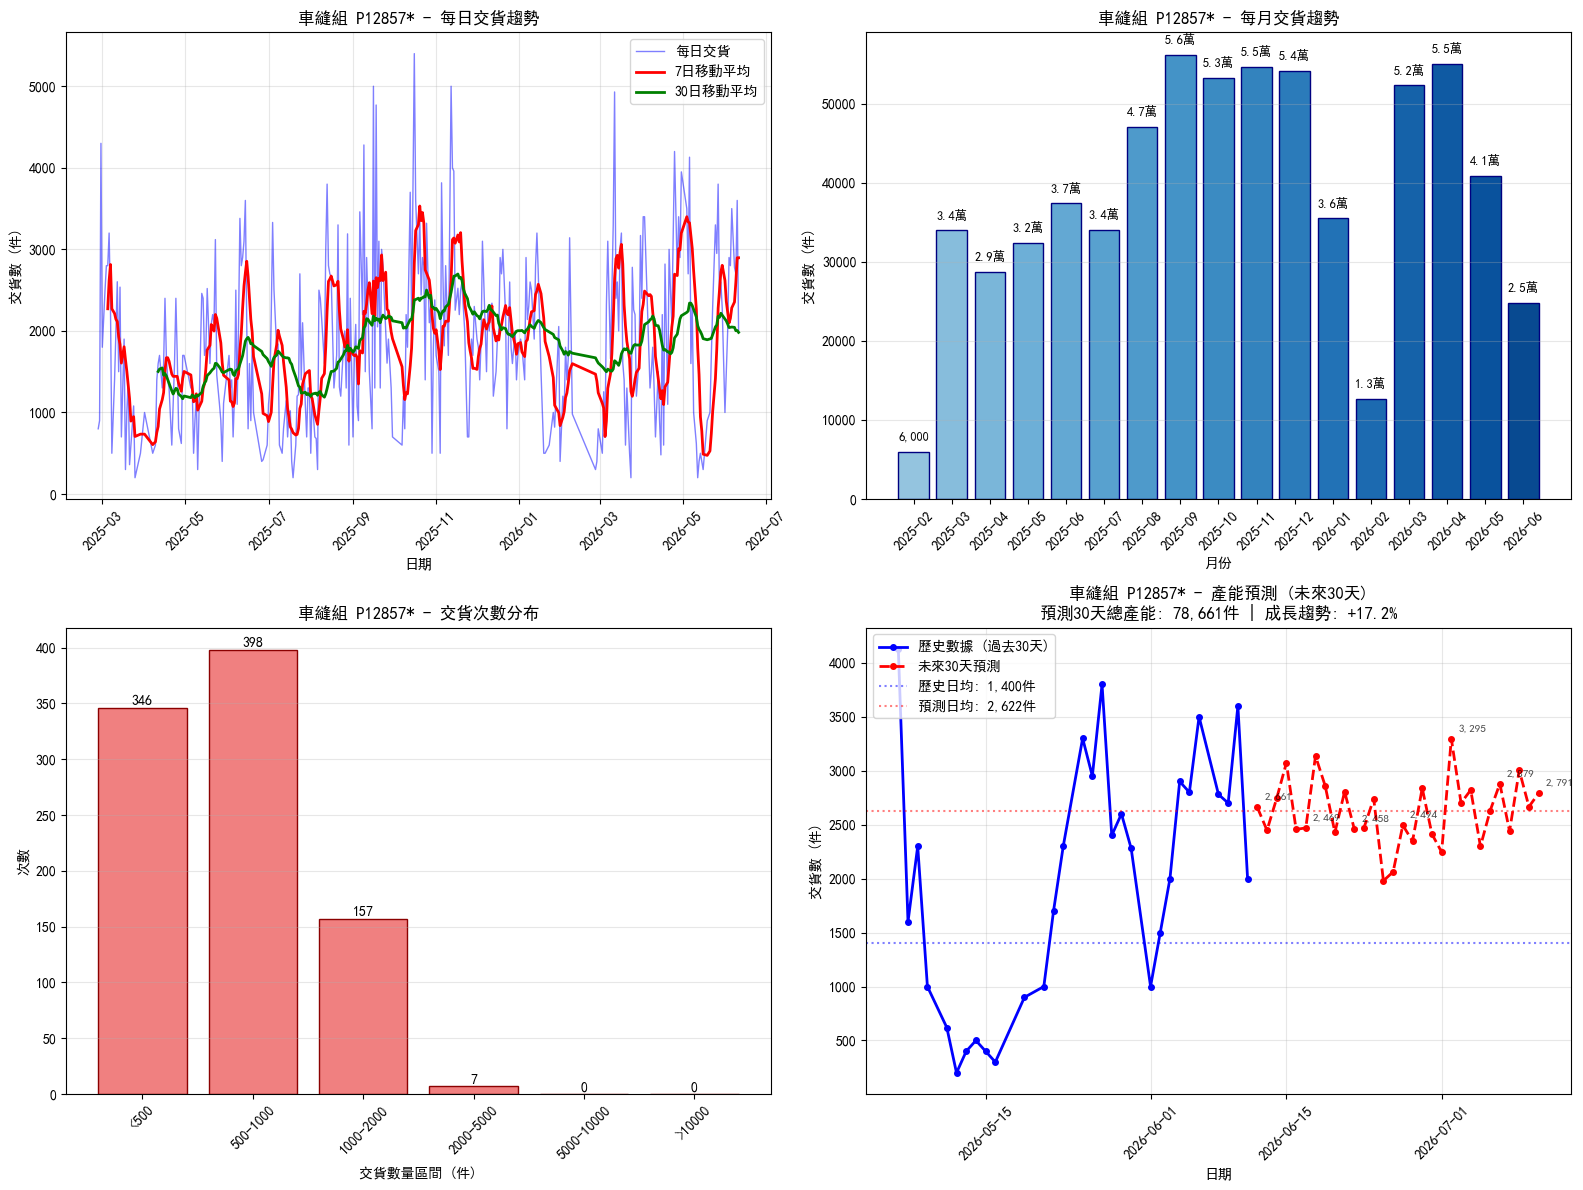


✅ 圖表已儲存為: 车缝组_P12857_产能预测.png

📁 匯出報表
✅ 報表已匯出至: 车缝组_P12857_产能报告\车缝组_P12857_生产报告.xlsx

📋 車縫組 + P12857* 產能預測摘要報告

📊 篩選條件:
   - 發出部門: 包含「車縫」
   - 款號: 以「P12857」開頭

📊 歷史統計:
   - 統計期間: 2025-02-26 ~ 2026-06-11
   - 總交貨件數: 659,290 件
   - 總交易次數: 908 次
   - 活躍天數: 352 天
   - 歷史日均產能: 1873 件/天
   - 涉及部門: ['車縫9組', '車縫4組', '車縫7組', '車縫5組']
   - 涉及款號: ['P12857-1', 'P12857-4', 'P12857-TD6', 'P12857-3A', 'P12857-TM10', 'P12857-TR2']

🔮 預測結果:
   - 使用模型: 趨勢調整加權移動平均
   - 預測未來30天總產能: 78,661 件
   - 預測未來30天日均產能: 2622 件/天

📈 產能趨勢: 預期成長 +40.0%
   💡 建議: 可考慮增加訂單量或優化排程

⚠️ 注意事項:
   1. 預測僅基於車縫組 + P12857* 的歷史交貨數據
   2. 未考慮訂單變化、人員異動、設備維護等因素
   3. 建議每週更新資料並重新預測
   4. 預測結果僅供參考，實際生產需結合現場狀況

📁 輸出檔案:
   - 车缝组_P12857_产能报告/车缝组_P12857_生产报告.xlsx
   - 车缝组_P12857_产能报告/车缝组_P12857_产能预测.png

✨ 分析完成！


In [18]:

# sewing_p12857_forecast.py
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime, timedelta
import warnings
import os
warnings.filterwarnings('ignore')

# 設置中文字體
plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

# 創建輸出資料夾
output_folder = '车缝组_P12857_产能报告'
if not os.path.exists(output_folder):
    os.makedirs(output_folder)
    print(f"📁 創建資料夾: {output_folder}")

# ============================================
# 1. 讀取 Excel 資料
# ============================================
print("=" * 70)
print("📊 車縫組 - 款號 P12857* 生產交貨資料分析與產能預測")
print("=" * 70)

# 讀取 Excel 檔案
file_path = r'C:\Users\Dell\Downloads\生产每日交货清单.xlsx'
print(f"\n📂 讀取檔案: {file_path}")

try:
    df_raw = pd.read_excel(file_path, sheet_name='生产每日交货清单')
    print(f"✅ 成功讀取 {len(df_raw)} 筆資料")
except FileNotFoundError:
    print(f"❌ 檔案不存在: {file_path}")
    print("請確認檔案路徑是否正確")
    exit()
except Exception as e:
    print(f"❌ 讀取失敗: {e}")
    exit()

# 檢查必要欄位
required_columns = ['开单日期', '发出部门', '交货数']
if '款号' not in df_raw.columns:
    print(f"⚠️ 警告: 資料中沒有「款號」欄位")
    print(f"   現有欄位: {df_raw.columns.tolist()}")

# 資料清理
df_raw['开单日期'] = pd.to_datetime(df_raw['开单日期'])
df_raw = df_raw.dropna(subset=['开单日期', '发出部门', '交货数'])
df_raw = df_raw[df_raw['交货数'] > 0]
df_raw = df_raw.sort_values('开单日期')

# ============================================
# 2. 篩選條件: 發出部門 LIKE '%車縫%' AND 款號 LIKE 'P12857%'
# ============================================
print("\n" + "=" * 70)
print("🔍 篩選條件:")
print("   - 發出部門 包含「車縫」")
print("   - 款號 以「P12857」開頭")
print("=" * 70)

# 篩選發出部門包含「車縫」的資料
sewing_mask = df_raw['发出部门'].str.contains('車縫', na=False)
df_sewing = df_raw[sewing_mask].copy()

print(f"\n📋 步驟1 - 篩選發出部門包含「車縫」:")
print(f"   - 符合條件的部門: {df_sewing['发出部门'].unique().tolist()}")
print(f"   - 資料筆數: {len(df_sewing)} 筆")

# 篩選款號以 P12857 開頭的資料
if '款号' in df_sewing.columns:
    p12857_mask = df_sewing['款号'].astype(str).str.startswith('P12857', na=False)
    df_filtered = df_sewing[p12857_mask].copy()
    print(f"\n📋 步驟2 - 篩選款號以「P12857」開頭:")
    print(f"   - 符合條件的款號: {df_filtered['款号'].unique().tolist()}")
    print(f"   - 資料筆數: {len(df_filtered)} 筆")
else:
    print(f"\n⚠️ 資料中沒有「款號」欄位，無法進行款號篩選")
    print(f"   將僅以發出部門包含「車縫」進行分析")
    df_filtered = df_sewing.copy()

# 檢查是否有資料
if len(df_filtered) == 0:
    print(f"\n❌ 沒有符合條件的資料！")
    if '款号' in df_sewing.columns:
        print(f"\n📋 所有車縫組的款號:")
        all_styles = df_sewing['款号'].unique()
        for s in all_styles[:20]:
            print(f"   - {s}")
        if len(all_styles) > 20:
            print(f"   ... 共 {len(all_styles)} 個款號")
    exit()

print(f"\n✅ 最終篩選結果:")
print(f"   - 總筆數: {len(df_filtered)} 筆")
print(f"   - 日期範圍: {df_filtered['开单日期'].min().strftime('%Y-%m-%d')} ~ {df_filtered['开单日期'].max().strftime('%Y-%m-%d')}")
print(f"   - 總交貨數: {df_filtered['交货数'].sum():,} 件")
print(f"   - 涉及部門: {df_filtered['发出部门'].unique().tolist()}")
if '款号' in df_filtered.columns:
    print(f"   - 涉及款號: {df_filtered['款号'].unique().tolist()}")

# ============================================
# 3. 添加時間維度欄位
# ============================================
df_filtered['日期'] = df_filtered['开单日期'].dt.date
df_filtered['年週'] = df_filtered['开单日期'].dt.strftime('%Y-W%W')
df_filtered['年月'] = df_filtered['开单日期'].dt.strftime('%Y-%m')
df_filtered['季度'] = df_filtered['开单日期'].dt.to_period('Q').astype(str)
df_filtered['年度'] = df_filtered['开单日期'].dt.year

# ============================================
# 4. 歷史統計報表
# ============================================
print("\n" + "=" * 70)
print("📈 歷史統計報表")
print("=" * 70)

# 日報
print("\n📅 日報 (所有交貨日期):")
daily = df_filtered.groupby(['日期'])['交货数'].sum().reset_index()
daily = daily.sort_values('日期', ascending=False)
print(daily.head(20).to_string(index=False))

# 週報
print("\n📆 週報:")
weekly = df_filtered.groupby(['年週'])['交货数'].sum().reset_index()
weekly = weekly.sort_values('年週', ascending=False)
print(weekly.head(15).to_string(index=False))

# 月報
print("\n📅 月報:")
monthly = df_filtered.groupby(['年月'])['交货数'].sum().reset_index()
monthly = monthly.sort_values('年月')
print(monthly.to_string(index=False))

# 季報
print("\n📊 季報:")
quarterly = df_filtered.groupby(['季度'])['交货数'].sum().reset_index()
quarterly = quarterly.sort_values('季度')
print(quarterly.to_string(index=False))

# 年報
print("\n📅 年報:")
yearly = df_filtered.groupby(['年度'])['交货数'].sum().reset_index()
print(yearly.to_string(index=False))

# ============================================
# 5. 依部門和款號統計
# ============================================
print("\n" + "=" * 70)
print("📊 依部門統計")
print("=" * 70)

dept_stats = df_filtered.groupby(['发出部门'])['交货数'].agg(['sum', 'mean', 'count']).round(2)
dept_stats.columns = ['總交貨數', '平均交貨數', '交易次數']
print(dept_stats)

if '款号' in df_filtered.columns:
    print("\n📊 依款號統計:")
    style_stats = df_filtered.groupby(['款号'])['交货数'].agg(['sum', 'mean', 'count']).round(2)
    style_stats.columns = ['總交貨數', '平均交貨數', '交易次數']
    style_stats = style_stats.sort_values('總交貨數', ascending=False)
    print(style_stats)

# ============================================
# 6. 詳細統計
# ============================================
print("\n" + "=" * 70)
print("📈 詳細統計")
print("=" * 70)

print(f"\n📊 基本統計:")
print(f"   - 總交貨件數: {df_filtered['交货数'].sum():,} 件")
print(f"   - 總交易次數: {len(df_filtered)} 次")
print(f"   - 平均每次交貨: {df_filtered['交货数'].mean():.0f} 件")
print(f"   - 最大單次交貨: {df_filtered['交货数'].max():,} 件")
print(f"   - 最小單次交貨: {df_filtered['交货数'].min():,} 件")
print(f"   - 標準差: {df_filtered['交货数'].std():.0f} 件")

# 交貨次數分布
print(f"\n📊 交貨次數分布:")
bins = [0, 500, 1000, 2000, 5000, 10000, 50000]
labels = ['<500', '500-1000', '1000-2000', '2000-5000', '5000-10000', '>10000']
df_filtered['交貨區間'] = pd.cut(df_filtered['交货数'], bins=bins, labels=labels)
count_dist = df_filtered['交貨區間'].value_counts().sort_index()
for interval, count in count_dist.items():
    print(f"   {interval} 件: {count} 次 ({count/len(df_filtered)*100:.1f}%)")

# 活躍天數統計
active_days = df_filtered['开单日期'].dt.date.nunique()
print(f"\n📅 時間統計:")
print(f"   - 活躍天數: {active_days} 天")
print(f"   - 日均交貨: {df_filtered['交货数'].sum() / active_days:.0f} 件/天")

# ============================================
# 7. 產能預測
# ============================================
print("\n" + "=" * 70)
print("🔮 產能預測 (未來30天)")
print("=" * 70)

def forecast_data(df_dept, forecast_days=30):
    """對篩選後的資料進行產能預測"""
    
    if len(df_dept) < 3:
        print(f"   ⚠️ 資料不足 (僅{len(df_dept)}筆)，無法進行可靠預測")
        return None
    
    # 按日期彙總每日交貨量
    daily_dept = df_dept.groupby('开单日期')['交货数'].sum().reset_index()
    daily_dept = daily_dept.set_index('开单日期')
    
    # 補齊缺失日期
    date_range = pd.date_range(start=daily_dept.index.min(), end=daily_dept.index.max(), freq='D')
    daily_dept = daily_dept.reindex(date_range, fill_value=0)
    daily_dept.columns = ['交货数']
    
    # 計算歷史統計
    historical_daily_avg = daily_dept['交货数'].mean()
    historical_total = daily_dept['交货数'].sum()
    
    # 計算移動平均
    window = min(7, len(daily_dept))
    if window > 0:
        ma = daily_dept['交货数'].rolling(window=window).mean().dropna()
        if len(ma) > 0:
            forecast_base = ma.iloc[-1]
        else:
            forecast_base = historical_daily_avg
    else:
        forecast_base = historical_daily_avg
    
    # 計算成長趨勢
    if len(daily_dept) >= 28:
        recent_14 = daily_dept['交货数'].tail(14).mean()
        older_14 = daily_dept['交货数'].head(14).mean()
        growth_rate = ((recent_14 - older_14) / older_14 * 100) if older_14 > 0 else 0
    elif len(daily_dept) >= 14:
        recent_7 = daily_dept['交货数'].tail(7).mean()
        older_7 = daily_dept['交货数'].head(7).mean()
        growth_rate = ((recent_7 - older_7) / older_7 * 100) if older_7 > 0 else 0
    else:
        growth_rate = 0
    
    # 預測
    forecast = []
    if abs(growth_rate) > 1:
        for i in range(forecast_days):
            trend_factor = 1 + (growth_rate / 100) * (i / forecast_days)
            forecast.append(max(0, forecast_base * trend_factor))
        model_name = "趨勢調整加權移動平均"
    else:
        for i in range(forecast_days):
            forecast.append(max(0, forecast_base))
        model_name = "簡單移動平均"
    
    # 添加自然波動
    if forecast_base > 0 and len(daily_dept) > 7:
        np.random.seed(42)
        noise_level = min(0.15, daily_dept['交货数'].std() / (forecast_base + 1) * 0.3)
        noise = np.random.normal(0, forecast_base * noise_level, forecast_days)
        forecast = [max(0, f + n) for f, n in zip(forecast, noise)]
    
    return {
        '模型': model_name,
        '历史总产能': round(historical_total, 0),
        '历史日均产能': round(historical_daily_avg, 0),
        '预测日均产能': round(np.mean(forecast), 0),
        '预测总产能': round(np.sum(forecast), 0),
        '增长趋势': round(growth_rate, 1),
        '预测值': forecast
    }

# 執行預測
result = forecast_data(df_filtered, forecast_days=30)

if result:
    print(f"\n📌 車縫組 + P12857* 預測結果:")
    print(f"   - 使用模型: {result['模型']}")
    print(f"   - 歷史總產能: {result['历史总产能']:,.0f} 件")
    print(f"   - 歷史日均產能: {result['历史日均产能']:.0f} 件/天")
    print(f"   - 預測未來30天日均產能: {result['预测日均产能']:.0f} 件/天")
    print(f"   - 預測未來30天總產能: {result['预测总产能']:,.0f} 件")
    print(f"   - 成長趨勢: {result['增长趋势']:+.1f}%")

# ============================================
# 8. 視覺化圖表
# ============================================
print("\n" + "=" * 70)
print("📈 繪製趨勢圖...")
print("=" * 70)

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 圖1: 每日交貨趨勢
daily_total = df_filtered.groupby('开单日期')['交货数'].sum()
daily_ma7 = daily_total.rolling(window=7).mean()
daily_ma30 = daily_total.rolling(window=30).mean()

axes[0,0].plot(daily_total.index, daily_total.values, 'b-', linewidth=1, alpha=0.5, label='每日交貨')
axes[0,0].plot(daily_ma7.index, daily_ma7.values, 'r-', linewidth=2, label='7日移動平均')
if len(daily_total) >= 30:
    axes[0,0].plot(daily_ma30.index, daily_ma30.values, 'g-', linewidth=2, label='30日移動平均')
axes[0,0].set_title('車縫組 P12857* - 每日交貨趨勢', fontsize=12, fontweight='bold')
axes[0,0].set_xlabel('日期')
axes[0,0].set_ylabel('交貨數 (件)')
axes[0,0].legend()
axes[0,0].tick_params(axis='x', rotation=45)
axes[0,0].grid(True, alpha=0.3)

# 圖2: 每月交貨趨勢（加上數量標籤）
monthly_total = df_filtered.groupby(df_filtered['开单日期'].dt.to_period('M'))['交货数'].sum()
months = range(len(monthly_total))
month_labels = [str(m) for m in monthly_total.index]
bar_colors = plt.cm.Blues(np.linspace(0.4, 0.9, len(monthly_total)))

bars = axes[0,1].bar(months, monthly_total.values, color=bar_colors, edgecolor='navy', linewidth=1)
axes[0,1].set_title('車縫組 P12857* - 每月交貨趨勢', fontsize=12, fontweight='bold')
axes[0,1].set_xlabel('月份')
axes[0,1].set_ylabel('交貨數 (件)')
axes[0,1].set_xticks(months)
axes[0,1].set_xticklabels(month_labels, rotation=45)
axes[0,1].grid(True, alpha=0.3, axis='y')

for bar, val in zip(bars, monthly_total.values):
    height = bar.get_height()
    if val >= 10000:
        label = f'{val/10000:.1f}萬'
    else:
        label = f'{int(val):,}'
    axes[0,1].text(bar.get_x() + bar.get_width()/2, height + max(monthly_total.values)*0.02,
                  label, ha='center', va='bottom', fontsize=9, fontweight='bold')

# 圖3: 交貨次數分布
bins = [0, 500, 1000, 2000, 5000, 10000, 50000]
labels = ['<500', '500-1000', '1000-2000', '2000-5000', '5000-10000', '>10000']
df_filtered['交貨區間'] = pd.cut(df_filtered['交货数'], bins=bins, labels=labels)
count_dist = df_filtered['交貨區間'].value_counts().sort_index()

bars = axes[1,0].bar(range(len(count_dist)), count_dist.values, color='lightcoral', edgecolor='darkred', linewidth=1)
axes[1,0].set_title('車縫組 P12857* - 交貨次數分布', fontsize=12, fontweight='bold')
axes[1,0].set_xlabel('交貨數量區間 (件)')
axes[1,0].set_ylabel('次數')
axes[1,0].set_xticks(range(len(count_dist)))
axes[1,0].set_xticklabels(count_dist.index, rotation=45)
axes[1,0].grid(True, alpha=0.3, axis='y')

for bar, val in zip(bars, count_dist.values):
    axes[1,0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                  str(val), ha='center', va='bottom', fontsize=10, fontweight='bold')

# 圖4: 產能預測
if result:
    last_30_days = daily_total.tail(30)
    forecast_values = result['预测值']
    
    if len(last_30_days) > 0:
        axes[1,1].plot(last_30_days.index, last_30_days.values, 'b-o', linewidth=2, markersize=4, label='歷史數據 (過去30天)')
    
    future_dates = pd.date_range(start=daily_total.index.max() + timedelta(days=1), periods=30, freq='D')
    axes[1,1].plot(future_dates, forecast_values, 'r--o', linewidth=2, markersize=4, label='未來30天預測')
    
    # 在預測點上添加數量標籤
    for i, (date, val) in enumerate(zip(future_dates, forecast_values)):
        if i % 5 == 0 or i == 29:
            if val >= 10000:
                label = f'{val/10000:.1f}萬'
            else:
                label = f'{int(val):,}'
            axes[1,1].annotate(label, xy=(date, val), xytext=(5, 5), 
                              textcoords='offset points', fontsize=8, alpha=0.7)
    
    hist_avg = result['历史日均产能']
    pred_avg = result['预测日均产能']
    axes[1,1].axhline(y=hist_avg, color='blue', linestyle=':', alpha=0.5, label=f'歷史日均: {hist_avg:,.0f}件')
    axes[1,1].axhline(y=pred_avg, color='red', linestyle=':', alpha=0.5, label=f'預測日均: {pred_avg:,.0f}件')
    
    axes[1,1].set_title(f'車縫組 P12857* - 產能預測 (未來30天)\n預測30天總產能: {result["预测总产能"]:,.0f}件 | 成長趨勢: {result["增长趋势"]:+.1f}%', 
                       fontsize=12, fontweight='bold')
    axes[1,1].set_xlabel('日期')
    axes[1,1].set_ylabel('交貨數 (件)')
    axes[1,1].legend(loc='upper left')
    axes[1,1].tick_params(axis='x', rotation=45)
    axes[1,1].grid(True, alpha=0.3)
else:
    axes[1,1].text(0.5, 0.5, '資料不足，無法預測', ha='center', va='center', transform=axes[1,1].transAxes, fontsize=14)
    axes[1,1].set_title('產能預測')

plt.tight_layout()
plt.savefig(os.path.join(output_folder, '车缝组_P12857_产能预测.png'), dpi=150, bbox_inches='tight', facecolor='white')
plt.show()

print("\n✅ 圖表已儲存為: 车缝组_P12857_产能预测.png")

# ============================================
# 9. 匯出報表
# ============================================
print("\n" + "=" * 70)
print("📁 匯出報表")
print("=" * 70)

output_file = os.path.join(output_folder, '车缝组_P12857_生产报告.xlsx')
try:
    with pd.ExcelWriter(output_file, engine='openpyxl') as writer:
        # 原始資料
        df_filtered.to_excel(writer, sheet_name='原始資料', index=False)
        
        # 日報
        daily_sorted = daily.sort_values('日期', ascending=False)
        daily_sorted.to_excel(writer, sheet_name='日報', index=False)
        
        # 週報
        weekly_sorted = weekly.sort_values('年週', ascending=False)
        weekly_sorted.to_excel(writer, sheet_name='週報', index=False)
        
        # 月報
        monthly.to_excel(writer, sheet_name='月報', index=False)
        
        # 季報
        quarterly.to_excel(writer, sheet_name='季報', index=False)
        
        # 年報
        yearly.to_excel(writer, sheet_name='年報', index=False)
        
        # 部門統計
        dept_stats.to_excel(writer, sheet_name='部門統計')
        
        if '款号' in df_filtered.columns:
            style_stats.to_excel(writer, sheet_name='款號統計')
        
        # 預測結果
        if result:
            # 每日預測明細
            forecast_dates = pd.date_range(start=daily_total.index.max() + timedelta(days=1), periods=30, freq='D')
            forecast_table = pd.DataFrame({
                '預測日期': forecast_dates,
                '預測交貨數': [round(v) for v in result['预测值']]
            })
            forecast_table.to_excel(writer, sheet_name='每日預測明細', index=False)
            
            forecast_summary = pd.DataFrame([{
                '資料範圍': '車縫組 + 款號P12857*',
                '預測模型': result['模型'],
                '歷史總產能(件)': result['历史总产能'],
                '歷史日均產能(件/天)': result['历史日均产能'],
                '預測30天總產能(件)': result['预测总产能'],
                '預測30天日均產能(件/天)': result['预测日均产能'],
                '成長趨勢(%)': result['增长趋势']
            }])
            forecast_summary.to_excel(writer, sheet_name='產能預測摘要', index=False)
        
        # 基本統計
        basic_stats = pd.DataFrame({
            '統計項目': ['總交貨件數', '總交易次數', '平均每次交貨', '最大單次交貨', '最小單次交貨', '標準差', '活躍天數', '日均交貨'],
            '數值': [
                f"{df_filtered['交货数'].sum():,}",
                len(df_filtered),
                f"{df_filtered['交货数'].mean():.0f}",
                f"{df_filtered['交货数'].max():,}",
                f"{df_filtered['交货数'].min():,}",
                f"{df_filtered['交货数'].std():.0f}",
                active_days,
                f"{df_filtered['交货数'].sum() / active_days:.0f}"
            ]
        })
        basic_stats.to_excel(writer, sheet_name='基本統計', index=False)
        
        # 交貨次數分布
        dist_stats = df_filtered['交貨區間'].value_counts().sort_index().reset_index()
        dist_stats.columns = ['交貨區間(件)', '次數']
        dist_stats.to_excel(writer, sheet_name='交貨次數分布', index=False)
    
    print(f"✅ 報表已匯出至: {output_file}")
except Exception as e:
    print(f"⚠️ 匯出Excel失敗: {e}")

# ============================================
# 10. 摘要報告
# ============================================
print("\n" + "=" * 70)
print("📋 車縫組 + P12857* 產能預測摘要報告")
print("=" * 70)

print(f"\n📊 篩選條件:")
print(f"   - 發出部門: 包含「車縫」")
print(f"   - 款號: 以「P12857」開頭")
print(f"\n📊 歷史統計:")
print(f"   - 統計期間: {df_filtered['开单日期'].min().strftime('%Y-%m-%d')} ~ {df_filtered['开单日期'].max().strftime('%Y-%m-%d')}")
print(f"   - 總交貨件數: {df_filtered['交货数'].sum():,} 件")
print(f"   - 總交易次數: {len(df_filtered)} 次")
print(f"   - 活躍天數: {active_days} 天")
print(f"   - 歷史日均產能: {df_filtered['交货数'].sum() / active_days:.0f} 件/天")
print(f"   - 涉及部門: {df_filtered['发出部门'].unique().tolist()}")
if '款号' in df_filtered.columns:
    print(f"   - 涉及款號: {df_filtered['款号'].unique().tolist()}")

if result:
    print(f"\n🔮 預測結果:")
    print(f"   - 使用模型: {result['模型']}")
    print(f"   - 預測未來30天總產能: {result['预测总产能']:,.0f} 件")
    print(f"   - 預測未來30天日均產能: {result['预测日均产能']:.0f} 件/天")
    
    hist_daily = df_filtered['交货数'].sum() / active_days
    pred_daily = result['预测日均产能']
    change_pct = (pred_daily - hist_daily) / hist_daily * 100
    
    if change_pct > 5:
        print(f"\n📈 產能趨勢: 預期成長 {change_pct:+.1f}%")
        print(f"   💡 建議: 可考慮增加訂單量或優化排程")
    elif change_pct < -5:
        print(f"\n📉 產能趨勢: 預期下降 {change_pct:+.1f}%")
        print(f"   ⚠️ 建議: 需關注訂單來源及生產效率")
    else:
        print(f"\n➡️ 產能趨勢: 相對穩定 ({change_pct:+.1f}%)")
        print(f"   💡 建議: 維持當前生產節奏")

print("\n" + "=" * 70)
print("⚠️ 注意事項:")
print("   1. 預測僅基於車縫組 + P12857* 的歷史交貨數據")
print("   2. 未考慮訂單變化、人員異動、設備維護等因素")
print("   3. 建議每週更新資料並重新預測")
print("   4. 預測結果僅供參考，實際生產需結合現場狀況")
print("=" * 70)

print(f"\n📁 輸出檔案:")
print(f"   - {output_folder}/车缝组_P12857_生产报告.xlsx")
print(f"   - {output_folder}/车缝组_P12857_产能预测.png")

print("\n✨ 分析完成！")

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime, timedelta
import warnings
import os
warnings.filterwarnings('ignore')

# 設置中文字體
plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

# 創建輸出資料夾
output_folder = '车缝组_P12857_移动平均预测报告'
if not os.path.exists(output_folder):
    os.makedirs(output_folder)
    print(f"📁 創建資料夾: {output_folder}")

# ============================================
# 1. 讀取 Excel 資料
# ============================================
print("=" * 80)
print("📊 車縫組 - 款號 P12857* 移動平均預測報告")
print("=" * 80)

# 讀取 Excel 檔案
file_path = r'C:\Users\Dell\Downloads\生产每日交货清单.xlsx'
print(f"\n📂 讀取檔案: {file_path}")

try:
    df_raw = pd.read_excel(file_path, sheet_name='生产每日交货清单')
    print(f"✅ 成功讀取 {len(df_raw)} 筆資料")
except FileNotFoundError:
    print(f"❌ 檔案不存在: {file_path}")
    print("請確認檔案路徑是否正確")
    exit()
except Exception as e:
    print(f"❌ 讀取失敗: {e}")
    exit()

# 檢查必要欄位
required_columns = ['开单日期', '发出部门', '交货数']
for col in required_columns:
    if col not in df_raw.columns:
        print(f"❌ 缺少必要欄位: {col}")
        exit()

# 資料清理：只保留交貨數 > 0 的記錄（交貨為0的不納入計算）
df_raw['开单日期'] = pd.to_datetime(df_raw['开单日期'])
df_raw = df_raw.dropna(subset=['开单日期', '发出部门', '交货数'])
df_raw = df_raw[df_raw['交货数'] > 0]  # 關鍵：只保留交貨數 > 0 的記錄
df_raw = df_raw.sort_values('开单日期')

# ============================================
# 2. 篩選條件: 發出部門 LIKE '%車縫%' AND 款號 LIKE 'P12857%'
# ============================================
print("\n" + "=" * 80)
print("🔍 篩選條件:")
print("   - 發出部門 包含「車縫」")
print("   - 款號 以「P12857」開頭")
print("   - 交貨數 > 0（只計算有交貨的日期）")
print("=" * 80)

# 篩選發出部門包含「車縫」的資料
sewing_mask = df_raw['发出部门'].str.contains('車縫', na=False)
df_sewing = df_raw[sewing_mask].copy()

print(f"\n📋 步驟1 - 篩選發出部門包含「車縫」:")
print(f"   - 符合條件的部門: {df_sewing['发出部门'].unique().tolist()}")
print(f"   - 有交貨的資料筆數: {len(df_sewing)} 筆")

# 篩選款號以 P12857 開頭的資料
if '款号' in df_sewing.columns:
    p12857_mask = df_sewing['款号'].astype(str).str.startswith('P12857', na=False)
    df_filtered = df_sewing[p12857_mask].copy()
    print(f"\n📋 步驟2 - 篩選款號以「P12857」開頭:")
    print(f"   - 符合條件的款號: {df_filtered['款号'].unique().tolist()}")
    print(f"   - 有交貨的資料筆數: {len(df_filtered)} 筆")
else:
    print(f"\n⚠️ 資料中沒有「款號」欄位，將僅以發出部門包含「車縫」進行分析")
    df_filtered = df_sewing.copy()

# 檢查是否有資料
if len(df_filtered) == 0:
    print(f"\n❌ 沒有符合條件的資料！")
    exit()

print(f"\n✅ 最終篩選結果:")
print(f"   - 有交貨記錄筆數: {len(df_filtered)} 筆")
print(f"   - 日期範圍: {df_filtered['开单日期'].min().strftime('%Y-%m-%d')} ~ {df_filtered['开单日期'].max().strftime('%Y-%m-%d')}")
print(f"   - 總交貨數: {df_filtered['交货数'].sum():,} 件")
print(f"   - 涉及部門: {df_filtered['发出部门'].unique().tolist()}")
if '款号' in df_filtered.columns:
    print(f"   - 涉及款號: {df_filtered['款号'].unique().tolist()}")

# ============================================
# 3. 準備每日彙總資料（只計算有交貨的天數）
# ============================================
print("\n" + "=" * 80)
print("📊 準備每日彙總資料（只計算有交貨的天數）")
print("=" * 80)

# 按日期彙總每日交貨量（只彙總有交貨的日期）
daily_total = df_filtered.groupby('开单日期')['交货数'].sum()

# 重要：這裡只計算有交貨的天數，不補0
# 總天數 = 有交貨的天數
total_days = len(daily_total)
active_days = total_days  # 因為只保留有交貨的日期，所以活躍天數 = 總天數
zero_delivery_days = 0  # 沒有交貨為0的日期被納入

print(f"\n📊 天數統計（只計算有交貨的日期）:")
print(f"   - 有交貨的天數（總天數）: {total_days} 天")
print(f"   - 活躍天數: {active_days} 天")
print(f"   - 交貨為0的天數: 不納入計算")
print(f"   - 日期範圍: {daily_total.index.min().strftime('%Y-%m-%d')} ~ {daily_total.index.max().strftime('%Y-%m-%d')}")

# 計算日均產能（使用有交貨的天數）
daily_avg = daily_total.mean()
total_delivery = daily_total.sum()

print(f"\n📊 產能統計:")
print(f"   - 總交貨量: {total_delivery:,.0f} 件")
print(f"   - 日均產能（基於有交貨天數）: {daily_avg:.0f} 件/天")
print(f"   - 最大單日交貨: {daily_total.max():,.0f} 件")
print(f"   - 最小單日交貨: {daily_total.min():,.0f} 件")
print(f"   - 標準差: {daily_total.std():.0f} 件")

# ============================================
# 4. 定義移動平均預測函數（基於有交貨的天數）
# ============================================
def moving_average_forecast(data, window, forecast_days=30):
    """使用移動平均進行預測（基於有交貨的天數）"""
    
    # 計算移動平均（只計算有交貨的數據點）
    ma = data.rolling(window=window, min_periods=1).mean()
    
    # 最後一個移動平均值作為預測基準
    last_ma = ma.iloc[-1]
    
    # 預測未來（使用最後的移動平均值）
    forecast = [last_ma] * forecast_days
    
    return {
        'window': window,
        'forecast': forecast,
        'last_ma': last_ma,
        'ma_series': ma,
        '历史日均': data.mean(),
        '历史总产能': data.sum(),
        '历史天数': len(data)
    }

# ============================================
# 5. 分別生成3、7、15、30天移動平均報告
# ============================================
print("\n" + "=" * 80)
print("🔮 分別生成移動平均預測報告 (3天、7天、15天、30天)")
print("=" * 80)

windows = [3, 7, 15, 30]
forecast_days = 30
forecast_results = {}

for window in windows:
    print(f"\n{'='*60}")
    print(f"📌 正在生成 {window}天移動平均預測報告")
    print(f"{'='*60}")
    
    # 計算預測
    result = moving_average_forecast(daily_total, window, forecast_days)
    forecast_results[window] = result
    
    # 計算預測總產能
    pred_total = sum(result['forecast'])
    pred_daily_avg = pred_total / forecast_days
    
    # 計算變化率
    change_pct = ((pred_daily_avg - result['历史日均']) / result['历史日均'] * 100) if result['历史日均'] > 0 else 0
    
    print(f"\n   📊 預測結果:")
    print(f"      - 移動平均窗口: {window} 天")
    print(f"      - 歷史有交貨天數: {result['历史天数']} 天")
    print(f"      - 最後移動平均值: {result['last_ma']:.0f} 件/天")
    print(f"      - 歷史日均產能: {result['历史日均']:.0f} 件/天")
    print(f"      - 預測30天總產能: {pred_total:.0f} 件")
    print(f"      - 預測30天日均產能: {pred_daily_avg:.0f} 件/天")
    print(f"      - 變化率: {change_pct:+.1f}%")
    
    # ============================================
    # 6. 生成該窗口的 Excel 報告
    # ============================================
    # 準備預測日期（從最後一個有交貨的日期後一天開始）
    future_dates = pd.date_range(start=daily_total.index.max() + timedelta(days=1), periods=forecast_days, freq='D')
    
    # 每日預測明細
    forecast_table = pd.DataFrame({
        '預測日期': future_dates,
        '預測交貨數': [round(v) for v in result['forecast']]
    })
    
    # 移動平均歷史數據
    ma_history = pd.DataFrame({
        '日期': daily_total.index,
        '實際交貨數': daily_total.values,
        f'{window}天移動平均': result['ma_series'].values
    })
    
    # 生成檔名
    safe_name = f'车缝组_P12857_{window}天MA'
    excel_file = os.path.join(output_folder, f'{safe_name}_预测报告.xlsx')
    
    try:
        with pd.ExcelWriter(excel_file, engine='openpyxl') as writer:
            # 預測摘要
            summary_df = pd.DataFrame([{
                '預測模型': f'{window}天移動平均',
                '移動平均窗口': f'{window}天',
                '歷史有交貨天數': result['历史天数'],
                '歷史總產能(件)': result['历史总产能'],
                '歷史日均產能(件/天)': round(result['历史日均'], 0),
                '最後移動平均值(件/天)': round(result['last_ma'], 0),
                '預測30天總產能(件)': round(pred_total, 0),
                '預測30天日均產能(件/天)': round(pred_daily_avg, 0),
                '產能變化率(%)': round(change_pct, 1),
                '預測起始日': future_dates[0].strftime('%Y-%m-%d'),
                '預測結束日': future_dates[-1].strftime('%Y-%m-%d'),
                '備註': '只計算有交貨的日期，交貨為0的天數不納入計算'
            }])
            summary_df.to_excel(writer, sheet_name='預測摘要', index=False)
            
            # 每日預測明細
            forecast_table.to_excel(writer, sheet_name='每日預測明細', index=False)
            
            # 移動平均歷史數據
            ma_history.to_excel(writer, sheet_name='移動平均歷史數據', index=False)
            
            # 原始篩選資料
            df_filtered.to_excel(writer, sheet_name='原始資料', index=False)
            
            # 統計分析
            stats_df = pd.DataFrame({
                '統計項目': [
                    '總交貨件數', 
                    '總交易次數', 
                    '平均每次交貨', 
                    '最大單次交貨', 
                    '最小單次交貨', 
                    '標準差',
                    '有交貨天數',
                    '歷史日均產能(基於有交貨天數)'
                ],
                '數值': [
                    f"{df_filtered['交货数'].sum():,}",
                    len(df_filtered),
                    f"{df_filtered['交货数'].mean():.0f}",
                    f"{df_filtered['交货数'].max():,}",
                    f"{df_filtered['交货数'].min():,}",
                    f"{df_filtered['交货数'].std():.0f}",
                    result['历史天数'],
                    f"{result['历史日均']:.0f}"
                ]
            })
            stats_df.to_excel(writer, sheet_name='統計分析', index=False)
            
            # 款號統計（如果有）
            if '款号' in df_filtered.columns:
                style_stats = df_filtered.groupby(['款号'])['交货数'].agg(['sum', 'mean', 'count']).round(2)
                style_stats.columns = ['總交貨數', '平均交貨數', '交易次數']
                style_stats = style_stats.sort_values('總交貨數', ascending=False)
                style_stats.to_excel(writer, sheet_name='款號統計')
            
            # 部門統計
            dept_stats = df_filtered.groupby(['发出部门'])['交货数'].agg(['sum', 'mean', 'count']).round(2)
            dept_stats.columns = ['總交貨數', '平均交貨數', '交易次數']
            dept_stats.to_excel(writer, sheet_name='部門統計')
        
        print(f"   ✅ Excel 報告已儲存: {excel_file}")
        
    except Exception as e:
        print(f"   ⚠️ Excel 匯出失敗: {e}")
    
    # ============================================
    # 7. 繪製該窗口的預測圖表
    # ============================================
    try:
        fig, axes = plt.subplots(2, 2, figsize=(16, 12))
        
        # 圖1: 歷史數據 + 移動平均
        axes[0,0].plot(daily_total.index, daily_total.values, 'b-o', linewidth=1, markersize=3, alpha=0.7, label='實際交貨量')
        axes[0,0].plot(daily_total.index, result['ma_series'], 'r-', linewidth=2, label=f'{window}天移動平均')
        axes[0,0].set_title(f'歷史數據與{window}天移動平均\n(共{len(daily_total)}個有交貨日期)', fontsize=12, fontweight='bold')
        axes[0,0].set_xlabel('日期')
        axes[0,0].set_ylabel('交貨數 (件)')
        axes[0,0].legend()
        axes[0,0].tick_params(axis='x', rotation=45)
        axes[0,0].grid(True, alpha=0.3)
        
        # 圖2: 每月交貨趨勢（加上數量標籤）
        df_filtered['年月'] = df_filtered['开单日期'].dt.strftime('%Y-%m')
        monthly_total = df_filtered.groupby('年月')['交货数'].sum()
        months = range(len(monthly_total))
        month_labels = [str(m) for m in monthly_total.index]
        
        bars = axes[0,1].bar(months, monthly_total.values, color='skyblue', edgecolor='navy', linewidth=1)
        axes[0,1].set_title('每月交貨趨勢', fontsize=12, fontweight='bold')
        axes[0,1].set_xlabel('月份')
        axes[0,1].set_ylabel('交貨數 (件)')
        axes[0,1].set_xticks(months)
        axes[0,1].set_xticklabels(month_labels, rotation=45)
        axes[0,1].grid(True, alpha=0.3, axis='y')
        
        for bar, val in zip(bars, monthly_total.values):
            height = bar.get_height()
            if val >= 10000:
                label = f'{val/10000:.1f}萬'
            else:
                label = f'{int(val):,}'
            axes[0,1].text(bar.get_x() + bar.get_width()/2, height + max(monthly_total.values)*0.02,
                          label, ha='center', va='bottom', fontsize=9, fontweight='bold')
        
        # 圖3: 交貨次數分布
        bins = [0, 500, 1000, 2000, 5000, 10000, 50000]
        labels = ['<500', '500-1000', '1000-2000', '2000-5000', '5000-10000', '>10000']
        df_filtered['交貨區間'] = pd.cut(df_filtered['交货数'], bins=bins, labels=labels)
        count_dist = df_filtered['交貨區間'].value_counts().sort_index()
        
        bars = axes[1,0].bar(range(len(count_dist)), count_dist.values, color='lightcoral', edgecolor='darkred')
        axes[1,0].set_title('交貨次數分布', fontsize=12, fontweight='bold')
        axes[1,0].set_xlabel('交貨數量區間 (件)')
        axes[1,0].set_ylabel('次數')
        axes[1,0].set_xticks(range(len(count_dist)))
        axes[1,0].set_xticklabels(count_dist.index, rotation=45)
        axes[1,0].grid(True, alpha=0.3, axis='y')
        
        for bar, val in zip(bars, count_dist.values):
            axes[1,0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                          str(val), ha='center', va='bottom', fontsize=10, fontweight='bold')
        
        # 圖4: 預測圖
        future_dates = pd.date_range(start=daily_total.index.max() + timedelta(days=1), periods=forecast_days, freq='D')
        forecast_values = result['forecast']
        
        # 顯示最近30天歷史數據
        last_30_days = daily_total.tail(30)
        if len(last_30_days) > 0:
            axes[1,1].plot(last_30_days.index, last_30_days.values, 'b-o', linewidth=2, markersize=4, label='歷史數據 (過去30個有交貨日)')
        
        axes[1,1].plot(future_dates, forecast_values, 'r--o', linewidth=2, markersize=4, label=f'{window}天移動平均預測')
        
        # 添加預測值標籤
        for i, (date, val) in enumerate(zip(future_dates, forecast_values)):
            if i % 5 == 0 or i == forecast_days - 1:
                axes[1,1].annotate(f'{int(val):,}', xy=(date, val), xytext=(5, 5), 
                                  textcoords='offset points', fontsize=8, alpha=0.7)
        
        # 添加平均值線
        hist_avg = result['历史日均']
        pred_avg = pred_daily_avg
        axes[1,1].axhline(y=hist_avg, color='blue', linestyle=':', alpha=0.5, label=f'歷史日均: {hist_avg:.0f}件')
        axes[1,1].axhline(y=pred_avg, color='red', linestyle=':', alpha=0.5, label=f'預測日均: {pred_avg:.0f}件')
        
        axes[1,1].set_title(f'{window}天移動平均預測 (未來30天)\n預測30天總產能: {pred_total:,.0f}件 | 變化率: {change_pct:+.1f}%', 
                           fontsize=12, fontweight='bold')
        axes[1,1].set_xlabel('日期')
        axes[1,1].set_ylabel('交貨數 (件)')
        axes[1,1].legend(loc='upper left')
        axes[1,1].tick_params(axis='x', rotation=45)
        axes[1,1].grid(True, alpha=0.3)
        
        plt.tight_layout()
        image_file = os.path.join(output_folder, f'{safe_name}_预测图表.png')
        plt.savefig(image_file, dpi=150, bbox_inches='tight', facecolor='white')
        plt.close()
        
        print(f"   ✅ 預測圖表已儲存: {image_file}")
        
    except Exception as e:
        print(f"   ⚠️ 圖表繪製失敗: {e}")
        plt.close()

# ============================================
# 8. 生成比較匯總報告
# ============================================
print("\n" + "=" * 80)
print("📊 生成移動平均預測比較匯總報告")
print("=" * 80)

# 匯總所有預測結果
comparison_data = []
for window in windows:
    result = forecast_results[window]
    pred_total = sum(result['forecast'])
    pred_daily = pred_total / forecast_days
    hist_daily = result['历史日均']
    change_pct = ((pred_daily - hist_daily) / hist_daily * 100) if hist_daily > 0 else 0
    
    comparison_data.append({
        '移動平均窗口': f'{window}天',
        '歷史有交貨天數': result['历史天数'],
        '最後移動平均值(件/天)': round(result['last_ma'], 0),
        '歷史日均產能(件/天)': round(hist_daily, 0),
        '預測30天總產能(件)': round(pred_total, 0),
        '預測30天日均產能(件/天)': round(pred_daily, 0),
        '產能變化率(%)': round(change_pct, 1),
        '預測穩定性': '高' if window >= 15 else '中' if window >= 7 else '低'
    })

comparison_df = pd.DataFrame(comparison_data)
comparison_file = os.path.join(output_folder, '00_移动平均预测比较汇总.xlsx')
try:
    with pd.ExcelWriter(comparison_file, engine='openpyxl') as writer:
        comparison_df.to_excel(writer, sheet_name='預測比較', index=False)
        
        # 添加說明
        note_df = pd.DataFrame({
            '說明項目': ['計算方式', '總天數定義', '活躍天數定義', '日均產能計算'],
            '說明內容': [
                '只統計交貨數 > 0 的記錄',
                '有交貨記錄的天數（不含交貨為0的天數）',
                '有交貨記錄的天數（與總天數相同）',
                '總交貨量 ÷ 有交貨天數'
            ]
        })
        note_df.to_excel(writer, sheet_name='計算說明', index=False)
        
        # 各窗口建議
        recommendation = pd.DataFrame({
            '移動平均窗口': ['3天', '7天', '15天', '30天'],
            '適用場景': [
                '短期波動大，適合快速反應，但預測穩定性較低',
                '平衡短期波動和穩定性，適合一般生產規劃',
                '平滑效果較好，適合中期生產計劃',
                '最平滑，適合長期趨勢分析，但反應較慢'
            ],
            '建議使用': ['適合日/週計劃', '適合週/月計劃', '適合月/季計劃', '適合季/年計劃']
        })
        recommendation.to_excel(writer, sheet_name='建議說明', index=False)
    
    print(f"✅ 比較匯總報告已儲存: {comparison_file}")
except Exception as e:
    print(f"⚠️ 比較匯總報告儲存失敗: {e}")

# ============================================
# 9. 最終摘要報告
# ============================================
print("\n" + "=" * 80)
print("📋 移動平均預測最終摘要報告")
print("=" * 80)

print(f"\n📊 資料篩選條件:")
print(f"   - 發出部門: 包含「車縫」")
print(f"   - 款號: 以「P12857」開頭")
print(f"   - 交貨數: > 0（只計算有交貨的記錄）")

print(f"\n📊 歷史資料統計（只計算有交貨的日期）:")
print(f"   - 有交貨天數: {total_days} 天")
print(f"   - 資料期間: {daily_total.index.min().strftime('%Y-%m-%d')} ~ {daily_total.index.max().strftime('%Y-%m-%d')}")
print(f"   - 歷史總產能: {total_delivery:,.0f} 件")
print(f"   - 歷史日均產能: {daily_avg:.0f} 件/天")

print(f"\n🔮 各窗口預測結果比較:")
print(f"{'='*80}")
print(f"{'窗口':<8} {'有交貨天數':<12} {'歷史日均':<12} {'預測總產能':<15} {'預測日均':<12} {'變化率':<10}")
print(f"{'-'*80}")

for window in windows:
    result = forecast_results[window]
    pred_total = sum(result['forecast'])
    pred_daily = pred_total / forecast_days
    hist_daily = result['历史日均']
    change_pct = ((pred_daily - hist_daily) / hist_daily * 100) if hist_daily > 0 else 0
    print(f"{window}天{'':<5} {result['历史天数']:>8}    {hist_daily:>8,.0f}    {pred_total:>12,.0f}    {pred_daily:>8,.0f}    {change_pct:>+7.1f}%")

print(f"{'='*80}")

print(f"\n📁 輸出檔案結構:")
print(f"\n{output_folder}/")
print("   ├── 00_移动平均预测比较汇总.xlsx    (所有窗口比較)")
print("   ├── 车缝组_P12857_3天MA_预测报告.xlsx")
print("   ├── 车缝组_P12857_3天MA_预测图表.png")
print("   ├── 车缝组_P12857_7天MA_预测报告.xlsx")
print("   ├── 车缝组_P12857_7天MA_预测图表.png")
print("   ├── 车缝组_P12857_15天MA_预测报告.xlsx")
print("   ├── 车缝组_P12857_15天MA_预测图表.png")
print("   ├── 车缝组_P12857_30天MA_预测报告.xlsx")
print("   └── 车缝组_P12857_30天MA_预测图表.png")

print("\n" + "=" * 80)
print("⚠️ 重要說明:")
print("   1. 本報告只統計交貨數 > 0 的記錄")
print("   2. 交貨為0的天數不納入計算（不影響總天數和活躍天數）")
print("   3. 日均產能 = 總交貨量 ÷ 有交貨天數")
print("   4. 移動平均計算只基於有交貨的日期")
print("   5. 3天MA反應最快，30天MA最平滑")
print("   6. 建議根據實際生產需求選擇合適的預測窗口")
print("=" * 80)

print("\n✨ 所有移動平均預測報告生成完成！")
print(f"📁 報告已儲存至: {os.path.abspath(output_folder)}")

📊 車縫組 - 款號 P12857* 移動平均預測報告

📂 讀取檔案: C:\Users\Dell\Downloads\生产每日交货清单.xlsx
✅ 成功讀取 5811 筆資料

🔍 篩選條件:
   - 發出部門 包含「車縫」
   - 款號 以「P12857」開頭
   - 交貨數 > 0（只計算有交貨的日期）

📋 步驟1 - 篩選發出部門包含「車縫」:
   - 符合條件的部門: ['車縫11組', '車縫8組', '車縫5組', '車縫2組', '車縫9組', '車縫4組', '車縫10組', '車縫7組', '車縫3組']
   - 有交貨的資料筆數: 5596 筆

📋 步驟2 - 篩選款號以「P12857」開頭:
   - 符合條件的款號: ['P12857-1', 'P12857-4', 'P12857-TD6', 'P12857-3A', 'P12857-TM10', 'P12857-TR2']
   - 有交貨的資料筆數: 908 筆

✅ 最終篩選結果:
   - 有交貨記錄筆數: 908 筆
   - 日期範圍: 2025-02-26 ~ 2026-06-11
   - 總交貨數: 659,290 件
   - 涉及部門: ['車縫9組', '車縫4組', '車縫7組', '車縫5組']
   - 涉及款號: ['P12857-1', 'P12857-4', 'P12857-TD6', 'P12857-3A', 'P12857-TM10', 'P12857-TR2']

📊 準備每日彙總資料（只計算有交貨的天數）

📊 天數統計（只計算有交貨的日期）:
   - 有交貨的天數（總天數）: 352 天
   - 活躍天數: 352 天
   - 交貨為0的天數: 不納入計算
   - 日期範圍: 2025-02-26 ~ 2026-06-11

📊 產能統計:
   - 總交貨量: 659,290 件
   - 日均產能（基於有交貨天數）: 1873 件/天
   - 最大單日交貨: 5,400 件
   - 最小單日交貨: 200 件
   - 標準差: 1018 件

🔮 分別生成移動平均預測報告 (3天、7天、15天、30天)

📌 正在生成 3天移動平均預測報告

   📊 預測結果:
      - 移動平均窗口: 3 天
  